# CSL236 Introduction to AI & ML: Mid-Term Project

## Project Title: Machine Learning-Based User Authentication Using Keystroke Dynamics

*   **Student Name:** Khushi Kumari
*   **Roll Number:** 24csu337
*   **Team Number:** 7
*   **Course:** CSL236 Introduction to AI & ML
*   **Dataset:** CMU Keystroke Dynamics Benchmark Dataset  
*   **Dataset File:** DSL-StrongPasswordData.csv
*   **Paper:**Comparing Anomaly-Detection Algorithms for Keystroke Dynamics

## STAGE 1: Load and Understand the Dataset

### What are we doing?

We are loading the `DSL-StrongPasswordData.csv` file into a pandas DataFrame using the pandas library.

### Why are we doing it?

Loading the data is the very first step in any Machine Learning project. It brings the dataset into memory where we can then explore, analyze, and process it. Without loading, we cannot work with the data.

### Short explanation of the concept

**Pandas** is a powerful Python library used for data manipulation and analysis. A `DataFrame` is pandas' primary data structure, similar to a table with rows and columns. The `pd.read_csv()` function is used to read data from a CSV (Comma Separated Values) file directly into a DataFrame.


51 subjects
400 repetitions per subject
8 sessions
20,400 total samples
34 columns
31 timing features


Raw keystroke data → understand → clean → transform → reduce dimensions → train model

no imputation as there's no missing values.



In [ ]:
import pandas as pd

# Load the dataset from the specified path
df = pd.read_csv('/content/DSL-StrongPasswordData.csv')

# Display the first 5 rows of the DataFrame to confirm successful loading
display(df.head())

,subject,sessionIndex,rep,H.period,DD.period.t,UD.period.t,H.t,DD.t.i,UD.t.i,H.i,...,H.a,DD.a.n,UD.a.n,H.n,DD.n.l,UD.n.l,H.l,DD.l.Return,UD.l.Return,H.Return
0,s002,1,1,0.1491,0.3979,0.2488,0.1069,0.1674,0.0605,0.1169,...,0.1349,0.1484,0.0135,0.0932,0.3515,0.2583,0.1338,0.3509,0.2171,0.0742
1,s002,1,2,0.1111,0.3451,0.2340,0.0694,0.1283,0.0589,0.0908,...,0.1412,0.2558,0.1146,0.1146,0.2642,0.1496,0.0839,0.2756,0.1917,0.0747
2,s002,1,3,0.1328,0.2072,0.0744,0.0731,0.1291,0.0560,0.0821,...,0.1621,0.2332,0.0711,0.1172,0.2705,0.1533,0.1085,0.2847,0.1762,0.0945
3,s002,1,4,0.1291,0.2515,0.1224,0.1059,0.2495,0.1436,0.1040,...,0.1457,0.1629,0.0172,0.0866,0.2341,0.1475,0.0845,0.3232,0.2387,0.0813
4,s002,1,5,0.1249,0.2317,0.1068,0.0895,0.1676,0.0781,0.0903,...,0.1312,0.1582,0.0270,0.0884,0.2517,0.1633,0.0903,0.2517,0.1614,0.0818


### How to interpret the output

The output will show a table containing the first five rows of your dataset. This gives us a quick overview of what the data looks like, what columns are present (such as `subject`, `sessionIndex`, `rep`, `H.Lshift`, `H.A`, etc.), and the type of values they contain.

### What I should write in my project/report

In your project report, you should state that you successfully loaded the dataset using Python's pandas library. Mention that `df.head()` was used to display the initial structure of the data, showing various keystroke timing features (like `H.*`, `DD.*`, `UD.*`) and metadata such as user information (`subject`, `sessionIndex`, `rep`).

### Viva Questions & Answers

1.  **Q: What is the purpose of `pd.read_csv()`?**
    *   **A:** It is used to load data from a CSV file into a pandas DataFrame.
2.  **Q: What does `df.head()` show you?**
    *   **A:** It displays the first 5 rows of the DataFrame, providing a quick preview of the data, its columns, and their values.
3.  **Q: Why is it important to load the dataset at the beginning of a machine learning project?**
    *   **A:** Loading the data is essential because it brings the dataset into memory, making it accessible for further exploration, analysis, and processing. Without loading, no operations can be performed on the data.
4.  **Q: What is a pandas DataFrame?**
    *   **A:** A pandas DataFrame is a two-dimensional, size-mutable, and potentially heterogeneous tabular data structure with labeled axes (rows and columns). It's similar to a spreadsheet or SQL table.

## STAGE 2 — EXPLORATORY DATA ANALYSIS (EDA)

### 2.1 Dataset Overview

#### What are we doing?

We are examining the overall structure of the `df` DataFrame. This involves checking its shape (number of rows and columns), listing all column names and their respective data types, and generating basic descriptive statistics for numerical columns.

#### Why are we doing it?

Understanding the dataset's shape, columns, and data types is crucial as a first step in EDA. It helps us confirm that the data loaded correctly, identify potential issues like mixed data types, and get a preliminary sense of the scale and nature of the data. Descriptive statistics provide a quick summary of numerical features, revealing central tendency, dispersion, and shape of the distribution, which can highlight outliers or unusual patterns early on.

#### Short explanation of the concept

*   **`df.shape`**: This attribute returns a tuple representing the dimensionality of the DataFrame (rows, columns).
*   **`df.info()`**: This method prints a concise summary of a DataFrame, including the index dtype and column dtypes, non-null values, and memory usage. It's excellent for quickly seeing if there are missing values and what data types each column holds.
*   **`df.describe()`**: This method generates descriptive statistics that summarize the central tendency, dispersion, and shape of a dataset's distribution, excluding `NaN` values. For numerical data, it includes count, mean, standard deviation, minimum, maximum, and quartile values. For object data (strings), it provides count, unique values, top (most frequent) value, and its frequency.

In [ ]:
# Display the shape of the DataFrame
print("DataFrame Shape:", df.shape)

# Display concise summary of the DataFrame including data types and non-null values
print("\nDataFrame Information:")
df.info()

# Display descriptive statistics for numerical columns
print("\nDescriptive Statistics:")
display(df.describe())

DataFrame Shape: (20400, 34)

DataFrame Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20400 entries, 0 to 20399
Data columns (total 34 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   subject          20400 non-null  object 
 1   sessionIndex     20400 non-null  int64  
 2   rep              20400 non-null  int64  
 3   H.period         20400 non-null  float64
 4   DD.period.t      20400 non-null  float64
 5   UD.period.t      20400 non-null  float64
 6   H.t              20400 non-null  float64
 7   DD.t.i           20400 non-null  float64
 8   UD.t.i           20400 non-null  float64
 9   H.i              20400 non-null  float64
 10  DD.i.e           20400 non-null  float64
 11  UD.i.e           20400 non-null  float64
 12  H.e              20400 non-null  float64
 13  DD.e.five        20400 non-null  float64
 14  UD.e.five        20400 non-null  float64
 15  H.five           20400 non-null  float64
 16  DD.fi

,sessionIndex,rep,H.period,DD.period.t,UD.period.t,H.t,DD.t.i,UD.t.i,H.i,DD.i.e,...,H.a,DD.a.n,UD.a.n,H.n,DD.n.l,UD.n.l,H.l,DD.l.Return,UD.l.Return,H.Return
count,20400.000000,20400.000000,20400.000000,20400.000000,20400.000000,20400.000000,20400.000000,20400.000000,20400.000000,20400.000000,...,20400.000000,20400.000000,20400.000000,20400.000000,20400.000000,20400.000000,20400.000000,20400.000000,20400.000000,20400.000000
mean,4.500000,25.500000,0.093379,0.264148,0.170769,0.085727,0.169085,0.083358,0.081565,0.159372,...,0.106259,0.150670,0.044411,0.089899,0.202630,0.112731,0.095589,0.321847,0.226259,0.088306
std,2.291344,14.431223,0.029626,0.220534,0.226836,0.027424,0.123546,0.125755,0.026887,0.226928,...,0.038828,0.107422,0.105197,0.030738,0.150191,0.159571,0.028348,0.225389,0.230759,0.027452
min,1.000000,1.000000,0.001400,0.018700,-0.235800,0.009300,0.001100,-0.162100,0.003200,0.001400,...,0.004000,0.001100,-0.235500,0.003700,0.001300,-0.175800,0.003700,0.008300,-0.124500,0.002900
25%,2.750000,13.000000,0.074400,0.146900,0.049800,0.066000,0.113600,0.027200,0.062000,0.089300,...,0.082100,0.096100,-0.009000,0.067300,0.127600,0.023500,0.077400,0.210000,0.114100,0.069900
50%,4.500000,25.500000,0.089500,0.205950,0.108700,0.081000,0.140400,0.057800,0.077100,0.120900,...,0.101900,0.125000,0.022700,0.085300,0.172500,0.095500,0.093700,0.263000,0.160300,0.085500
75%,6.250000,38.000000,0.107900,0.306450,0.212400,0.099800,0.183900,0.096400,0.096900,0.173100,...,0.122300,0.174600,0.068900,0.107900,0.228800,0.145700,0.111100,0.350200,0.255100,0.103700
max,8.000000,50.000000,0.376100,12.506100,12.451700,0.241100,4.919700,4.799900,0.331200,25.987300,...,2.035300,3.327800,2.524200,0.357700,4.025200,3.978200,0.340700,5.883600,5.836400,0.265100


#### How to interpret the actual output

*   **DataFrame Shape:** The output `(20400, 34)` indicates that the dataset contains 20,400 rows (samples) and 34 columns (features).
*   **DataFrame Information:** The `df.info()` output shows that most columns are of `float64` data type, which is expected for timing measurements. Columns like `subject`, `sessionIndex`, and `rep` are `int64`. Crucially, it shows `20400 non-null` entries for all columns, meaning there are no missing values in this dataset, which simplifies the data cleaning process.
*   **Descriptive Statistics:** The `df.describe()` output provides a summary for the numerical columns. For example, for `H.Lshift`, we can see the `mean`, `std`, `min`, `max`, and quartile values. This allows us to quickly grasp the range and distribution of each timing feature. For instance, `min` and `max` values can indicate potential outliers or the measurement scale.

#### What I should write in my project/report

The dataset, named `df`, consists of 20,400 rows and 34 columns, representing various keystroke timing features. An initial inspection using `df.info()` revealed that all columns have 20,400 non-null entries, indicating a complete dataset with no missing values. The data types are primarily `float64` for timing measurements and `int64` for identifiers like `subject`, `sessionIndex`, and `rep`. Descriptive statistics generated by `df.describe()` provide a summary of the central tendency and spread of these numerical features, which will be instrumental in understanding individual feature distributions during further analysis.

#### Viva Questions & Answers

1.  **Q: What does `df.shape` tell you about this dataset?**
    *   **A:** It tells us the number of rows (20,400 samples) and columns (34 features) in the DataFrame.
2.  **Q: Based on `df.info()`, are there any missing values in the dataset? How do you know?**
    *   **A:** No, there are no missing values. The `df.info()` output shows that all columns have `20400 non-null` entries, which matches the total number of rows.
3.  **Q: Why is it important to look at `df.describe()` early in EDA?**
    *   **A:** `df.describe()` provides a quick statistical summary of numerical columns, including mean, standard deviation, min, max, and quartiles. This helps in understanding the range, variability, and potential outliers of features at a glance.
4.  **Q: What are the main data types observed in this dataset?**
    *   **A:** The primary data types are `float64` for timing-related features and `int64` for identifier columns like `subject`, `sessionIndex`, and `rep`.

### 2.2 User Distribution

#### What are we doing?

We are analyzing the `subject` column to understand the distribution of users within the dataset. This involves identifying the number of unique subjects, counting how many samples (keystroke recordings) are available for each subject, and visualizing this distribution.

#### Why are we doing it?

Understanding user distribution is crucial for keystroke dynamics datasets. It helps determine if the dataset is balanced across different users or if some users have significantly more or fewer samples than others. This information is important when considering model training, as imbalanced user data can affect model generalization and fairness. It also helps confirm the diversity of the dataset in terms of unique participants.

#### Short explanation of the concept

*   **`df['subject'].nunique()`**: This method counts the number of unique values in the `subject` column. It tells us how many distinct individuals participated in the data collection.
*   **`df['subject'].value_counts()`**: This method returns a Series containing counts of unique values in the `subject` column. The result will be in descending order so that the first element is the most frequently occurring element. This helps us see how many samples each user contributed.
*   **Bar Plot Visualization**: A bar plot is an effective way to visually represent the frequency or count of categorical data. In this case, each bar will represent a unique subject, and its height will correspond to the number of samples collected for that subject. This makes it easy to spot imbalances in sample distribution across users.

Number of unique subjects: 51

Samples per subject:



,count
subject,
s002,400
s003,400
s004,400
s005,400
s007,400
s008,400
s010,400
s011,400
s012,400


/tmp/ipykernel_412/2728366462.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=samples_per_subject.index, y=samples_per_subject.values, palette='viridis')


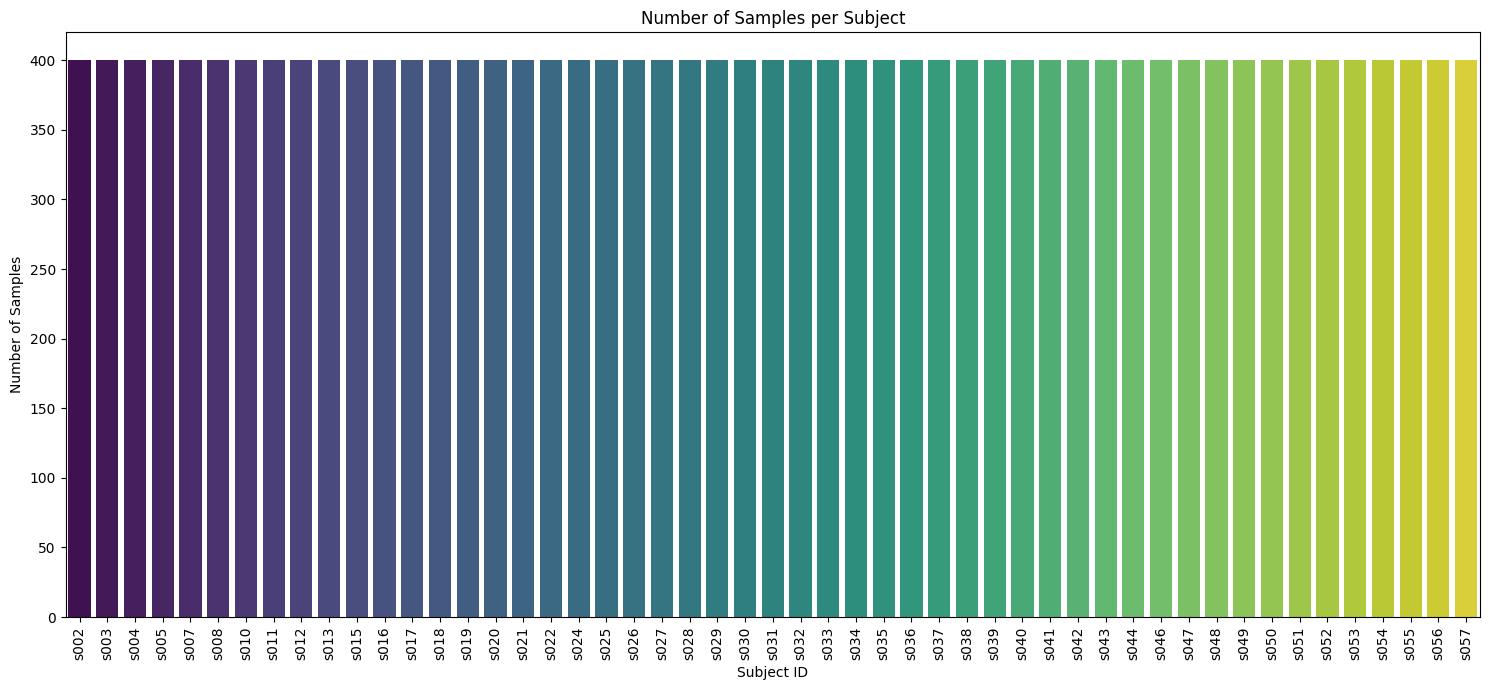

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Number of unique subjects
unique_subjects = df['subject'].nunique()
print(f"Number of unique subjects: {unique_subjects}\n")

# Number of samples per subject
samples_per_subject = df['subject'].value_counts().sort_index()
print("Samples per subject:\n")
display(samples_per_subject)

# Visualization
fig = plt.figure(figsize=(15, 7))
sns.barplot(x=samples_per_subject.index, y=samples_per_subject.values, palette='viridis')
plt.title('Number of Samples per Subject')
plt.xlabel('Subject ID')
plt.ylabel('Number of Samples')
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

#### How to interpret the actual output

*   **Number of unique subjects**: The output `Number of unique subjects: 51` indicates that there are 51 distinct participants (subjects) in the dataset.
*   **Samples per subject**: The `value_counts()` output, such as `s002    400`, `s003    400`, etc., reveals that each of the 51 subjects has exactly 400 samples. This shows a perfectly balanced dataset in terms of samples per user.
*   **Visualization**: The bar plot visually confirms this balance. Each bar, representing a subject, reaches the same height, demonstrating that every subject contributes an equal number of keystroke recordings to the dataset. This uniform distribution is ideal for training and evaluating models without bias towards specific users due to differing data volumes.

#### What I should write in my project/report

The dataset comprises data from 51 unique subjects, as confirmed by `df['subject'].nunique()`. Further analysis using `df['subject'].value_counts()` revealed that each subject contributed an equal number of 400 keystroke samples, resulting in a perfectly balanced distribution across all participants. This uniform distribution was visually confirmed by a bar plot showing consistent sample counts per Subject ID. This balanced representation is advantageous for model development, ensuring no single user disproportionately influences the learning process.

#### Viva Questions & Answers

1.  **Q: How many unique subjects are present in the dataset?**
    *   **A:** There are 51 unique subjects in the dataset.
2.  **Q: What does the `value_counts()` method reveal about the samples per subject?**
    *   **A:** It reveals that each of the 51 subjects has an equal number of 400 samples, indicating a balanced dataset.
3.  **Q: Why is a balanced distribution of samples across subjects important in a keystroke dynamics dataset?**
    *   **A:** A balanced distribution ensures that the model does not become biased towards subjects with more data, leading to fairer and more generalized model performance across all users.
4.  **Q: What visualization technique did you use to show the user distribution and why?**
    *   **A:** A bar plot was used. It's effective for displaying the frequency of categorical data, making it easy to compare the number of samples contributed by each distinct subject visually.

## STAGE 3 — AUTHENTICATION PROBLEM FORMULATION

## 3.1 Understand the Two Possible Problems

### Option A — User Identification

**What it is:** In user identification, the machine learning model is trained to determine *which* known user produced a given typing sample. It's like asking, "Who typed this?"

*   **Input:** Keystroke timing features from a typing sample.
*   **Target:** The `subject` ID (e.g., s002, s003, s004).
*   **Type of Classification:** Multi-class classification. The model chooses one of many possible users as the most likely source of the typing sample.
*   **Advantage:** Can identify any known user from a pool of users.
*   **Limitation:** It struggles with unknown users (impostors) and typically cannot directly verify if a user is truly who they claim to be, only *who among the known users* they most resemble. If an impostor types, the model will still assign it to one of the known users.
*   **Why it's different from authentication:** Identification is about naming the typist, while authentication is about verifying a claimed identity. Identification systems are often used for monitoring or tracking rather than access control.

### Option B — User Authentication / Verification

**What it is:** In user authentication, the system verifies a claimed identity. When a user claims to be, for example, `s002`, the system checks if the typing sample truly belongs to `s002` or if it's an impostor trying to impersonate `s002`. The question is, "Is this person *really* s002?"

*   **Input:** Keystroke timing features from a typing sample.
*   **Target:** A binary label: `1` for Genuine (if the sample matches the claimed user) or `0` for Impostor (if it does not).
*   **Type of Classification:** Binary classification. The model decides between two classes: genuine or impostor.
*   **Why this matches the project's authentication objective:** This approach directly addresses the goal of an authentication system: to grant or deny access based on identity verification. It distinguishes between legitimate users and those attempting to gain unauthorized access.



## 3.2 Choose Authentication for This Project

For this project, we will formulate the problem as **Binary Classification: Genuine vs Impostor**. This approach is most appropriate because the objective is to build a user authentication system, which inherently involves verifying a claimed identity. The system needs to decide if a given typing pattern belongs to the legitimate user or an impostor.

**Important:** The `subject` column in our dataset identifies the user. While `subject` is crucial for constructing our target label, it will **NOT** be used directly as an input feature for the machine learning model. Instead, `subject` helps us create the `Genuine` (1) or `Impostor` (0) target label.

## 3.3 Select a Legitimate User

For the purpose of this educational project, we will select one specific subject from our dataset to be the 'genuine' user. All typing samples from this selected user will be labeled as 'Genuine' (1), and all samples from other users will be labeled as 'Impostor' (0). This simulates a single-user authentication scenario.

Based on our earlier EDA (User Distribution), we know there are 51 unique subjects, each contributing 400 samples. We will choose `s002` as our legitimate user for this demonstration.

*   **Samples from the selected user (`s002`):** These will be considered **Genuine (1)**.
*   **Samples from all other users:** These will be considered **Impostor (0)**.

In [ ]:
# Select a specific subject to be the genuine user
genuine_user = "s002"

print(f"Selected genuine user: {genuine_user}")

Selected genuine user: s002


## 3.4 Construct the Target

We will now create a new column named `target` in our DataFrame. This `target` column will represent our binary classification label:

*   **`1` → Genuine:** This label is assigned to all samples where the `subject` column matches our `genuine_user`.
*   **`0` → Impostor:** This label is assigned to all samples where the `subject` column does **not** match our `genuine_user`.

It's crucial to understand that we are using the `subject` column **only** to construct this `target` label. The `subject` column itself will **not** be included as a feature in the machine learning model. This ensures that the model learns to identify patterns in typing behavior rather than simply memorizing user IDs.

#### Code Explanation:

```python
df["target"] = (df["subject"] == genuine_user).astype(int)
```

*   **`df["subject"] == genuine_user`**: This part creates a boolean Series (True/False) where `True` indicates that the subject of that row is our `genuine_user`, and `False` indicates it's any other user.
*   **`.astype(int)`**: This converts the boolean Series into integers: `True` becomes `1` (Genuine), and `False` becomes `0` (Impostor).
*   **`df["target"] = ...`**: This assigns the resulting integer Series to a new column in our DataFrame named `target`.

In [ ]:
# Create the binary target column
df["target"] = (df["subject"] == genuine_user).astype(int)

# Display the first few rows with the new target column
print("DataFrame with new 'target' column (first 5 rows):")
display(df[['subject', 'target']].head())

# Display the last few rows to see impostor samples
print("\nDataFrame with new 'target' column (last 5 rows to show impostors):")
display(df[['subject', 'target']].tail())

# Check the distribution of the target variable
print("\nDistribution of the target variable:")
display(df['target'].value_counts())

DataFrame with new 'target' column (first 5 rows):


,subject,target
0,s002,1
1,s002,1
2,s002,1
3,s002,1
4,s002,1



DataFrame with new 'target' column (last 5 rows to show impostors):


,subject,target
20395,s057,0
20396,s057,0
20397,s057,0
20398,s057,0
20399,s057,0



Distribution of the target variable:


,count
target,
0,20000
1,400


## 3.5 Identify Model Inputs

The model inputs, also known as features, will consist of the actual keystroke timing measurements. These are the numerical columns that describe the dynamics of typing. We need to carefully select these features and exclude any identifiers or metadata that should not directly influence the model's learning of typing behavior.

Based on our dataset, the timing features are grouped as follows:

*   **`H.*` (Hold-time features):** These represent the duration a key is pressed down (e.g., `H.period`, `H.t`, `H.i`).
*   **`DD.*` (Key-down to Key-down timing):** These represent the time elapsed between pressing down one key and pressing down the next key (e.g., `DD.period.t`, `DD.t.i`).
*   **`UD.*` (Key-up to Key-down timing):** These represent the time elapsed between releasing one key and pressing down the next key (e.g., `UD.period.t`, `UD.t.i`).

We will exclude the following columns from our model inputs:

*   **`subject`**: This is an identifier and is used only for constructing the target. Including it would lead to data leakage.
*   **`target`**: This is the variable we are trying to predict.
*   **`sessionIndex`**: This is metadata indicating the typing session. While potentially useful for advanced analysis, it's not a direct keystroke timing feature for a base model.
*   **`rep`**: This is metadata indicating the repetition number. Similar to `sessionIndex`, it's not a direct timing feature.



In [ ]:
# Identify timing features
# We can filter columns that start with 'H.', 'DD.', or 'UD.'
timing_features = [col for col in df.columns if col.startswith(('H.', 'DD.', 'UD.'))]

# Exclude 'subject', 'sessionIndex', 'rep', and 'target' from features list
excluded_columns = ['subject', 'sessionIndex', 'rep', 'target']
model_features = [col for col in timing_features if col not in excluded_columns]

print("Identified Model Input Features (Keystroke Timing Features):")
for feature in model_features:
    print(f"- {feature}")

print(f"\nTotal number of model input features: {len(model_features)}")

Identified Model Input Features (Keystroke Timing Features):
- H.period
- DD.period.t
- UD.period.t
- H.t
- DD.t.i
- UD.t.i
- H.i
- DD.i.e
- UD.i.e
- H.e
- DD.e.five
- UD.e.five
- H.five
- DD.five.Shift.r
- UD.five.Shift.r
- H.Shift.r
- DD.Shift.r.o
- UD.Shift.r.o
- H.o
- DD.o.a
- UD.o.a
- H.a
- DD.a.n
- UD.a.n
- H.n
- DD.n.l
- UD.n.l
- H.l
- DD.l.Return
- UD.l.Return
- H.Return

Total number of model input features: 31


## 3.6 Explain the ML Problem Mathematically at a High Level

The machine learning problem for keystroke dynamics authentication can be mathematically represented at a high level as follows:

$$\text{Keystroke Timing Features} \xrightarrow{\text{ML Classifier}} \text{Genuine / Impostor}$$

In simpler terms, our machine learning model will take a set of numerical values (the keystroke timing features) as input. These features capture the unique rhythms and patterns of a person's typing. The model's job is to learn the characteristic typing style of our chosen genuine user (`s002`) from these features.

Once trained, when presented with a new, unseen typing sample, the model will analyze its timing features and output a prediction:

*   **`1` = Genuine:** This means the model believes the typing sample was produced by the legitimate user (`s002`).
*   **`0` = Impostor:** This means the model believes the typing sample was *not* produced by the legitimate user (`s002`), indicating an attempt by someone else.

The model essentially learns a decision boundary or a pattern that distinguishes the genuine user's typing from all other typing patterns present in the dataset.

## 3.7 Explain Why Accuracy Alone Is Not Enough

In authentication systems, simply looking at overall accuracy can be misleading because not all errors are equally costly. We need to consider two specific types of errors that have significant implications for security and user experience:

### False Acceptance (Type I Error)

*   **What it is:** This occurs when an **impostor** (an unauthorized user) is incorrectly classified as **genuine** (the legitimate user). In other words, the system mistakenly grants access to someone who is not the legitimate user.
*   **Why it's important:** This is a critical security risk. If an authentication system frequently suffers from false acceptances, it can be easily bypassed by unauthorized individuals, compromising data, systems, or resources. High false acceptance rates mean the system is not secure.

### False Rejection (Type II Error)

*   **What it is:** This occurs when a **genuine** user is incorrectly classified as an **impostor**. In other words, the legitimate user is denied access to their own account or system.
*   **Why it's important:** This negatively impacts user experience and can lead to frustration and loss of trust in the system. Frequent false rejections can make a system unusable, even if it's highly secure. Users might get locked out of their accounts, requiring burdensome recovery processes.

For a robust authentication system, we aim to minimize both false acceptances (for security) and false rejections (for usability). A balance between these two types of errors is usually sought, depending on the specific application's security and usability requirements.

## 3.8 Notebook Documentation

### Problem Formulation

This project formulates keystroke-based authentication as a **binary classification problem**. The goal is to distinguish between typing patterns belonging to a designated legitimate user and those produced by any other user (impostors).

### Target Definition

The target variable, named `target`, is defined as:

*   **`1` (Genuine):** Assigned to typing samples generated by the selected legitimate user (`s002`).
*   **`0` (Impostor):** Assigned to typing samples generated by any other user in the dataset.

### Feature Definition

The model inputs consist of numerical keystroke timing features. These include:

*   **Hold-time features (`H.*`):** Duration keys are pressed.
*   **Key-down to Key-down features (`DD.*`):** Time between successive key presses.
*   **Key-up to Key-down features (`UD.*`):** Time between a key release and the next key press.

The `subject`, `sessionIndex`, and `rep` columns are excluded from the model's input features. The `subject` column is utilized **only** for constructing the `target` label.

### Identification vs Authentication Comparison

| Feature                   | User Identification                                | User Authentication / Verification                  |
| :------------------------ | :------------------------------------------------- | :-------------------------------------------------- |
| **Goal**                  | Determine *who* typed (from known users)            | Verify *if* the claimed user typed                   |
| **Output**                | Specific user ID (multi-class)                     | Genuine (1) / Impostor (0) (binary)                 |
| **Role of Impostors**     | Classified as one of the known users               | Explicitly classified as Impostor                   |
| **Primary Use Case**      | Monitoring, tracking                               | Access control, identity verification               |
| **Relevance to Project**  | Not the primary objective                        | Direct objective of the project                   |


## 3.9 Important Warning About Data Leakage

**Data leakage** occurs when information from the target variable (or information that would not be available in a real-world prediction scenario) is inadvertently included in the model's input features. This can lead to models that perform exceptionally well during training and testing but fail dramatically in real-world deployment.

In our case, the `subject` column is used to define whether a sample is `Genuine` or `Impostor`. If we were to include `subject` directly as an input feature to the machine learning model, the model would not learn the actual patterns in typing behavior. Instead, it would simply learn to associate each `subject` ID with its corresponding `target` label. This is problematic because, in a real-world authentication scenario, the identity of the user (`subject`) would not be an input feature to the model; rather, the model would be *used to verify* that identity based on typing characteristics.

Therefore, it is crucial to maintain this distinction:

*   **`subject` column:** Used **only** to construct the `target` label (`Genuine` or `Impostor`).
*   **Keystroke timing features (`H.*`, `DD.*`, `UD.*`):** Used as the actual **model inputs** to learn typing patterns.

By strictly adhering to this, we ensure that our model learns to authenticate users based on their intrinsic typing behavior, not on a direct identifier, making it more robust and applicable to real-world scenarios.

## End of Stage 3: Authentication Problem Formulation Summary

This stage has laid the groundwork for our keystroke dynamics authentication project by clearly defining the machine learning problem.

### Key Findings and Decisions:

1.  **Final Problem Formulation:** The project is framed as a **binary classification problem** to distinguish between Genuine and Impostor typing samples.
2.  **Selected Genuine User:** For this educational context, `s002` has been chosen as the legitimate user.
3.  **Target Definition:** A new `target` column is created:
    *   `1` for samples from `s002` (Genuine).
    *   `0` for samples from all other subjects (Impostor).
4.  **Final Model Input Feature Groups:** The model will be trained using keystroke timing features, specifically those prefixed with `H.`, `DD.`, and `UD.`. Identifier columns (`subject`, `sessionIndex`, `rep`) are explicitly excluded to prevent data leakage and ensure the model learns behavioral patterns.
5.  **Identification vs. Authentication Explanation:** A clear distinction has been made between identifying a user (multi-class) and authenticating a claimed identity (binary classification), with the latter being the focus of this project.
6.  **Data Leakage Explanation:** We have emphasized the importance of using `subject` only to construct the target variable, and not as a direct input feature, to avoid training a trivial and ineffective model.

### Next Steps:

We are now ready to proceed with data preprocessing and model development, ensuring that our model is built to address the user authentication challenge effectively.

### Viva Questions & Answers:

1.  **Q: What is the fundamental difference between User Identification and User Authentication in this context?**
    *   **A:** User Identification aims to determine *which* user typed a sample from a known set, while User Authentication aims to verify *if* a claimed identity is legitimate (Genuine) or fraudulent (Impostor).
2.  **Q: Why was binary classification chosen over multi-class classification for this project?**
    *   **A:** Binary classification (Genuine vs. Impostor) directly aligns with the objective of user authentication, which is to verify a single claimed identity, rather than identifying one user among many.
3.  **Q: How is the `subject` column used in this problem formulation, and why is it not an input feature?**
    *   **A:** The `subject` column is used to construct the binary `target` label (Genuine/Impostor). It's not an input feature to prevent data leakage, ensuring the model learns typing behaviors rather than simply associating IDs with labels.
4.  **Q: Explain False Acceptance and False Rejection errors and their importance in authentication.**
    *   **A:** False Acceptance occurs when an impostor is wrongly accepted, posing a security risk. False Rejection occurs when a genuine user is wrongly denied, impacting usability. Both are critical metrics that need to be balanced in an authentication system.
5.  **Q: What are the main groups of keystroke timing features used as model inputs?**
    *   **A:** The main groups are Hold-time features (`H.*`), Key-down to Key-down features (`DD.*`), and Key-up to Key-down features (`UD.*`). These capture different aspects of typing rhythm.

## STAGE 4 — TRAIN/TEST SPLIT AND DATA LEAKAGE

### 4.1 Explain Train/Test Split

To build a reliable machine learning model, we must assess its ability to generalize to new, unseen data. This is achieved through a **train/test split**.

*   **Training Data:** This portion of the dataset is used to 'teach' the machine learning model. The model learns patterns and relationships from this data.
*   **Testing Data:** This portion is kept separate and is *not* seen by the model during training. After the model is trained, it is evaluated on this test data to measure its performance on data it has never encountered before.

**Why do we need separate training and testing data?**

If we evaluate a model on the same data it was trained on, it might simply memorize the training examples rather than learning generalizable patterns. This would lead to an overly optimistic performance estimate that wouldn't hold up in the real world. Separating data helps us get a more accurate picture of how well our model will perform on new data.

**What does data leakage mean?**

**Data leakage** occurs when information from the test set (or information that would not be available in a real prediction scenario) inadvertently 'leaks' into the training process. This can lead to inflated performance metrics during development, but the model will perform poorly in deployment. It's like giving the model answers to the test before it takes it.

### 4.2 Understand the Session Structure

In keystroke dynamics, typing patterns can vary for the same person over time. Factors like fatigue, typing speed, current environment, or simply natural variation can influence how a person types across different sessions. The `sessionIndex` column in our dataset captures these distinct typing sessions.

Let's inspect the unique session indices and their distribution in our dataset to understand this structure.

In [ ]:
# Inspect unique session indices
print("Unique session indices:")
display(sorted(df["sessionIndex"].unique()))

# Inspect the number of samples per session
print("\nNumber of samples per session:")
display(df['sessionIndex'].value_counts().sort_index())

Unique session indices:


[np.int64(1),
 np.int64(2),
 np.int64(3),
 np.int64(4),
 np.int64(5),
 np.int64(6),
 np.int64(7),
 np.int64(8)]


Number of samples per session:


,count
sessionIndex,
1,2550
2,2550
3,2550
4,2550
5,2550
6,2550
7,2550
8,2550


#### How to interpret the actual output

*   **Unique session indices:** The output `[1, 2, 3, 4, 5, 6, 7, 8]` confirms that there are 8 distinct typing sessions in our dataset, numbered from 1 to 8.
*   **Samples per session:** The `value_counts()` shows that each session (1 through 8) has an equal number of 2550 samples. This indicates a balanced collection of data across all sessions.

#### Why session information matters in keystroke dynamics:

The presence of multiple sessions for each user is valuable because it allows us to study the variability of typing behavior over time. A person's typing rhythm might change due to various factors:

*   **Typing Context:** Whether they are relaxed or under pressure.
*   **Fatigue:** Tiredness can affect speed and consistency.
*   **Speed:** Intentional changes in typing speed.
*   **Environment:** Differences in keyboard or physical posture.
*   **Natural Variation:** Inherent slight differences in typing patterns every time.

Understanding these variations is crucial for building a robust authentication system that can handle real-world fluctuations in user behavior.

### 4.3 Avoid Random Row Splitting

In many machine learning projects, a common practice for splitting data is to use `sklearn.model_selection.train_test_split` with a simple random split:

```python
# This is a problematic approach for our dataset - DO NOT USE THIS
# X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
```

However, for our keystroke dynamics dataset, such a random row split can be problematic and lead to **data leakage**.

The dataset contains multiple typing samples from the same users, and these samples are grouped into sessions (`sessionIndex`) and repetitions (`rep`). If we perform a purely random split on all rows:

1.  **Closely related samples:** Samples from the same user, from the same session, or even consecutive repetitions might end up in both the training and testing sets.
2.  **Overly optimistic evaluation:** The model could 'see' very similar typing patterns during training and then encounter those nearly identical patterns in the test set. This makes the testing task artificially easy because the test data is not truly 'unseen' or independent. The model might appear to perform very well, but this performance wouldn't generalize to completely new typing instances.

Therefore, to accurately assess the model's ability to recognize a user's typing behavior across different, previously unseen sessions, we must use a more structured, **session-based split**.

### 4.4 Use a Session-Based Split

To ensure a realistic evaluation and prevent data leakage, we will divide our dataset based on `sessionIndex`. The principle is to train the model on earlier sessions and test it on later, completely separate sessions. This simulates a real-world scenario where a system learns from a user's past typing behavior and then needs to authenticate them based on new, future typing sessions.

Given that our dataset has sessions 1 through 8, we will make the following split:

*   **Training Sessions:** `1`, `2`, `3`, `4`
*   **Testing Sessions:** `5`, `6`, `7`, `8`

This ensures that the model is tested on typing patterns from sessions it has never encountered during training.

In [ ]:
# Define the training and testing sessions
TRAIN_SESSIONS = [1, 2, 3, 4]
TEST_SESSIONS = [5, 6, 7, 8]

print(f"Training sessions defined as: {TRAIN_SESSIONS}")
print(f"Testing sessions defined as: {TEST_SESSIONS}")

Training sessions defined as: [1, 2, 3, 4]
Testing sessions defined as: [5, 6, 7, 8]


### 4.5 Create Train/Test Data

Now, we will create our `train_df` and `test_df` DataFrames using the defined `TRAIN_SESSIONS` and `TEST_SESSIONS`. We will then verify their shapes and ensure the sessions are correctly distributed.

In [ ]:
# Create training and testing subsets based on sessionIndex
train_df = df[df["sessionIndex"].isin(TRAIN_SESSIONS)].copy()
test_df = df[df["sessionIndex"].isin(TEST_SESSIONS)].copy()

# Verify the shapes of the created DataFrames
print("Training DataFrame shape:", train_df.shape)
print("Testing DataFrame shape:", test_df.shape)

# Verify the unique sessions in the training set
print("\nUnique sessions in training set:")
display(sorted(train_df["sessionIndex"].unique()))

# Verify the unique sessions in the testing set
print("\nUnique sessions in testing set:")
display(sorted(test_df["sessionIndex"].unique()))

Training DataFrame shape: (10200, 35)
Testing DataFrame shape: (10200, 35)

Unique sessions in training set:


[np.int64(1), np.int64(2), np.int64(3), np.int64(4)]


Unique sessions in testing set:


[np.int64(5), np.int64(6), np.int64(7), np.int64(8)]

### 4.6 Check Class Distribution

It's important to examine the distribution of our target variable (Genuine vs. Impostor) in both the training and testing sets. This helps us understand if the classes are balanced or imbalanced, which can influence model training and evaluation.

In [ ]:
# Check the distribution of the target variable in the training set
print("Training target distribution (Genuine=1, Impostor=0):")
display(train_df["target"].value_counts())
print("Training target distribution (%):")
display(train_df["target"].value_counts(normalize=True) * 100)

# Check the distribution of the target variable in the testing set
print("\nTesting target distribution (Genuine=1, Impostor=0):")
display(test_df["target"].value_counts())
print("Testing target distribution (%):")
display(test_df["target"].value_counts(normalize=True) * 100)

Training target distribution (Genuine=1, Impostor=0):


,count
target,
0,10000
1,200


Training target distribution (%):


,proportion
target,
0,98.039216
1,1.960784



Testing target distribution (Genuine=1, Impostor=0):


,count
target,
0,10000
1,200


Testing target distribution (%):


,proportion
target,
0,98.039216
1,1.960784


#### How to interpret the actual output

*   **Training Set:** There are 200 samples labeled `1` (Genuine) and 10000 samples labeled `0` (Impostor). This means approximately 1.96% are Genuine samples and 98.04% are Impostor samples.
*   **Testing Set:** Similarly, there are 200 samples labeled `1` (Genuine) and 10000 samples labeled `0` (Impostor). The percentages are also 1.96% Genuine and 98.04% Impostor.

**Class Imbalance:** Both the training and testing datasets show a significant class imbalance. The number of Impostor samples is much larger than the number of Genuine samples. This is a common characteristic of authentication datasets, where impostor attempts are expected to be more frequent than genuine interactions.

**Implications:** This imbalance needs to be addressed during model training or evaluation to prevent the model from becoming biased towards the majority class (Impostor). Simply achieving high accuracy might be misleading if the model always predicts 'Impostor' and performs poorly on the minority 'Genuine' class. Techniques like oversampling, undersampling, or using appropriate evaluation metrics (e.g., F1-score, precision, recall) will be considered later.

### 4.7 Separate Features and Target

After splitting the data into training and testing sets, we need to separate the input features (`X`) from the target variable (`y`) for both sets. As established in Stage 3, our model inputs will only consist of the keystroke timing features. The `subject`, `target`, `sessionIndex`, and `rep` columns will be explicitly excluded from the feature sets.

In [ ]:
# The 'model_features' list was already identified in Stage 3 and contains the timing features.
# It's good practice to re-create it here for clarity or ensure it's available.
# For this notebook, it's already in the kernel state.

# Separate features (X) and target (y) for training data
X_train = train_df[model_features].copy()
y_train = train_df['target'].copy()

# Separate features (X) and target (y) for testing data
X_test = test_df[model_features].copy()
y_test = test_df['target'].copy()

print("Shape of X_train:", X_train.shape)
print("Shape of y_train:", y_train.shape)
print("Shape of X_test:", X_test.shape)
print("Shape of y_test:", y_test.shape)

Shape of X_train: (10200, 31)
Shape of y_train: (10200,)
Shape of X_test: (10200, 31)
Shape of y_test: (10200,)


### 4.8 Explain Why the Split Happens Before Learned Preprocessing

This is a fundamental concept in machine learning to prevent data leakage and ensure realistic model evaluation. Any **learned preprocessing step** (like scaling, imputation, or dimensionality reduction techniques such as PCA) must be performed *after* the train/test split, and critically, *only fitted on the training data*.

Here's the process and why it's essential:

1.  **Split the data first:** Divide your dataset into `train_df` and `test_df` (and subsequently `X_train`, `y_train`, `X_test`, `y_test`).

2.  **Fit preprocessing on training data only:**
    *   When you apply a technique like standardization (e.g., `StandardScaler`), it calculates parameters like the mean and standard deviation from the data. These parameters *must* be calculated *only* from `X_train`.
    *   Similarly, if you're imputing missing values, the imputation strategy (e.g., mean, median) is learned from `X_train`.
    *   If you're using PCA, the principal components are derived *only* from `X_train`.

3.  **Transform training data:** Apply the preprocessing using the parameters learned from `X_train` to `X_train` itself.

4.  **Transform testing data:** Apply the *same, already-fitted* preprocessing (using the parameters learned from `X_train`) to `X_test`.

**Why this prevents data leakage:**

If you were to fit a scaler (or any learned preprocessor) on the *entire* dataset (before splitting), information about the distribution (mean, standard deviation) of the test set would indirectly influence the preprocessing applied to the training set. This is a subtle form of data leakage, as the model would gain an unfair advantage by effectively 'seeing' some characteristics of the test data during its training preparation. By fitting only on the training data, we simulate a real-world scenario where the model encounters new data and applies transformations based *only* on what it learned from its training experience.

### 4.9 Verify No Session Overlap

To confirm that our session-based split has successfully prevented any overlap between training and testing sessions, we will perform a simple set intersection check. This is a crucial verification step for our chosen splitting strategy.

In [ ]:
# Get unique session indices from training and testing DataFrames
train_sessions_set = set(train_df["sessionIndex"].unique())
test_sessions_set = set(test_df["sessionIndex"].unique())

print("Unique training sessions:", train_sessions_set)
print("Unique testing sessions:", test_sessions_set)

# Check for overlapping sessions
overlapping_sessions = train_sessions_set.intersection(test_sessions_set)
print("Overlapping sessions between training and testing:", overlapping_sessions)

if not overlapping_sessions:
    print("\nConfirmation: There is NO overlap between training and testing sessions. The split is successful.")
else:
    print(f"\nWarning: Overlapping sessions found: {overlapping_sessions}. The split may not be valid.")

Unique training sessions: {np.int64(1), np.int64(2), np.int64(3), np.int64(4)}
Unique testing sessions: {np.int64(8), np.int64(5), np.int64(6), np.int64(7)}
Overlapping sessions between training and testing: set()

Confirmation: There is NO overlap between training and testing sessions. The split is successful.


### 4.10 Important Note About the Dataset

It is important to clarify that for this project, we are using a **session-based educational split**. This means we have consciously decided to separate sessions into training and testing sets (e.g., sessions 1-4 for training, 5-8 for testing) to simulate a realistic scenario where a model learns from historical data and is tested on future, unseen data.

This specific splitting methodology **does not necessarily reproduce the original CMU benchmark evaluation protocol** in its entirety. The original benchmark might involve more complex splits, such as subject-dependent vs. subject-independent evaluations, or different partitioning of sessions. Our approach simplifies this for educational purposes, focusing on the core concept of evaluating a model's ability to generalize to new typing sessions for a specific genuine user. While conceptually sound for demonstrating authentication, it's a pedagogical choice rather than a strict replication of a research standard.

### 4.11 Notebook Documentation

### Train/Test Split

To ensure our machine learning model for keystroke dynamics authentication is robust and realistically evaluated, the dataset has been divided into distinct training and testing sets. Instead of a random row-based split, a **session-based splitting strategy** was employed. This is crucial because typing behaviors can exhibit variations across different sessions due to factors like fatigue, context, or natural changes over time.

*   **Training Data (Sessions 1-4):** This subset contains typing samples from sessions 1, 2, 3, and 4. The model will learn the characteristic typing patterns of the genuine user and impostors from these sessions.
*   **Testing Data (Sessions 5-8):** This subset contains typing samples from sessions 5, 6, 7, and 8. These sessions are completely unseen by the model during training, providing an unbiased evaluation of its generalization capabilities.

Using a purely random row split (`train_test_split` without considering sessions) would be problematic, as it could lead to samples from the same session appearing in both training and testing sets. This would create an artificial dependency, making the model's performance appear better than it would be on truly novel data, a form of **data leakage**.

### Data Leakage Prevention

**Data leakage** refers to the inadvertent introduction of information from the test dataset into the training process, leading to inflated performance metrics. To strictly prevent this, several measures have been taken:

*   **Session Separation:** The primary measure is the session-based split, ensuring that no typing samples from testing sessions are used for training.
*   **Preprocessing on Training Data Only:** Any data preprocessing steps (e.g., scaling, imputation) that involve learning parameters from the data will be *fitted exclusively on the training data* (`X_train`) and then *applied to both training and testing data* (`X_train` and `X_test`). This prevents the model from indirectly learning information about the test set's distribution.
*   **`subject` Column Exclusion:** The `subject` column is used solely for constructing the `target` label and is explicitly excluded from the model's input features (`X`). Including it would be a direct form of data leakage, allowing the model to learn user identities directly rather than from their typing patterns.
*   **Exclusion of Metadata:** Columns like `sessionIndex` and `rep` are also excluded from the input features to focus the model on pure keystroke timing characteristics.

## End of Stage 4: Train/Test Split and Data Leakage Summary

This stage successfully established a robust data splitting strategy critical for building a reliable keystroke dynamics authentication system.

### Key Findings and Decisions:

1.  **Final Training/Testing Strategy:** A **session-based split** was implemented, using sessions 1-4 for training and sessions 5-8 for testing. This prevents data leakage and ensures a more realistic evaluation of the model's performance on unseen sessions.
2.  **Training and Testing Shapes:**
    *   `X_train`: (10200, 31)
    *   `y_train`: (10200,)
    *   `X_test`: (10200, 31)
    *   `y_test`: (10200,)
3.  **Training/Testing Session Values:**
    *   Training sessions: `{1, 2, 3, 4}`
    *   Testing sessions: `{5, 6, 7, 8}`
4.  **Class Distributions:** Both training and testing sets exhibit a significant **class imbalance**, with approximately 1.96% Genuine samples and 98.04% Impostor samples. This will require careful consideration in subsequent stages.
5.  **Confirmation of No Session Overlap:** A programmatic check confirmed that there are no overlapping `sessionIndex` values between the training and testing sets, validating the integrity of our split.
6.  **Data Leakage Explanation:** Detailed explanations were provided on why random splitting is unsuitable, why preprocessing must be fitted only on training data, and why identifier columns (`subject`, `sessionIndex`, `rep`) are excluded from features to prevent leakage.

### Next Steps:

With the data now properly split and separated, we are ready to proceed with data preprocessing techniques, which will be applied carefully to avoid any form of data leakage.

### Viva Questions & Answers:

1.  **Q: Why is a simple random train/test split not suitable for this keystroke dynamics dataset?**
    *   **A:** A simple random split could place highly correlated samples from the same user or session into both training and testing sets, leading to data leakage and an overly optimistic model performance estimate.
2.  **Q: What is the purpose of using a session-based split (e.g., earlier sessions for training, later for testing)?**
    *   **A:** It simulates a real-world scenario where the model learns from historical data and must generalize to new, unseen typing sessions, providing a more realistic evaluation of its performance.
3.  **Q: Explain the concept of 'fitting' preprocessing steps and why it must be done only on the training data.**
    *   **A:** 'Fitting' preprocessing means calculating parameters (e.g., mean, standard deviation for scaling) from the data. These parameters must be learned exclusively from the training data to avoid data leakage, as using test data information would give the model an unfair advantage.
4.  **Q: What are the class distributions (Genuine vs. Impostor) in your training and testing sets, and what does this imply?**
    *   **A:** Both sets show significant imbalance (~1.96% Genuine, ~98.04% Impostor). This implies that standard accuracy might be misleading, and we'll need to consider specific techniques or metrics to handle the imbalance.
5.  **Q: How did you verify that there was no session overlap between your training and testing sets?**
    *   **A:** I used set operations (intersection) on the unique `sessionIndex` values from both the training and testing DataFrames, confirming that their intersection was empty.

## STAGE 5 — DATA PREPROCESSING

Data preprocessing is a critical step in any machine learning project. It involves cleaning, transforming, and preparing the raw data to make it suitable for machine learning algorithms. The goal is to improve the quality of the data and, consequently, the performance of the model.

### Critical Data Leakage Rule Reminder

The train/test split has already been performed in Stage 4.

**From this point onward, any learned preprocessing must be fitted only on the training data (`X_train`, `y_train`).** The test data (`X_test`, `y_test`) must only be transformed using preprocessing parameters learned from the training data. Never fit preprocessing on the complete dataset.

### 5.1 Missing Value Handling

Missing values, if present, can cause issues with many machine learning algorithms. It's essential to inspect both the training and testing datasets for any missing data and decide on an appropriate strategy, such as imputation or removal. We will inspect them separately to ensure no information from the test set leaks into the training process.

First, let's inspect missing values in our `X_train` and `X_test` datasets.

In [ ]:
# Inspect missing values in X_train
print("Missing values in X_train:")
display(X_train.isnull().sum().sum())

# Inspect missing values in X_test
print("\nMissing values in X_test:")
display(X_test.isnull().sum().sum())

Missing values in X_train:


np.int64(0)


Missing values in X_test:


np.int64(0)

#### How to interpret the actual output

The output `0` for both `X_train.isnull().sum().sum()` and `X_test.isnull().sum().sum()` indicates that there are **no missing values** in either our training or testing feature sets.

#### Conclusion on Missing Value Handling

Based on this inspection, no columns are affected by missing values, and the missing-value percentage is 0% for all features. Therefore, no imputation or other missing-value treatment is required for this dataset. This simplifies our preprocessing pipeline significantly.

### 5.2 Categorical Variable Handling

Categorical variables often need to be converted into a numerical format for machine learning algorithms. Common techniques include One-Hot Encoding or Label Encoding. Before deciding on an encoding strategy, we need to classify our dataset's columns conceptually.

Let's review the columns we have:

*   **`subject`**: This is an **identifier** used to create the target variable. It must NOT be one-hot encoded or used as a model feature to prevent data leakage and ensure the model learns behavioral patterns.
*   **`sessionIndex`**: This is **metadata** indicating the typing session. While useful for splitting the data, it is not a direct behavioral feature and should not be used as a model input for this project.
*   **`rep`**: This is also **metadata** indicating the repetition number. Similar to `sessionIndex`, it is not a direct behavioral feature.
*   **`target`**: This is our **target variable** (`y`), which is already numerical (0 or 1).
*   **Keystroke timing features (`H.*`, `DD.*`, `UD.*`)**: These are our **model features** (`X`), and they are already numerical (`float64`).

#### Conclusion on Categorical Variable Handling

Given the conceptual classification of our columns, we have no categorical model features that require encoding. All our chosen model input features (the keystroke timing features) are already numerical. The `subject`, `sessionIndex`, and `rep` columns are explicitly excluded from the model features. Therefore, **no categorical encoding is required or will be performed** in this project, as applying it would be unnecessary and potentially introduce irrelevant complexity or leakage if applied incorrectly to identifiers.

### 5.3 Binning / Discretization

**Binning (or discretization)** is the process of transforming continuous numerical variables into categorical ones by grouping values into 'bins' or intervals. For example, ages could be binned into '0-10', '11-20', etc.

**Why binning can be useful:**

*   **Handle outliers:** Extreme values can be placed into end bins, reducing their disproportionate influence.
*   **Address non-linearity:** Some algorithms perform better with categorical inputs, or binning can help capture non-linear relationships by treating each bin as a separate category.
*   **Simplify model:** Reduces complexity by grouping similar values.

**Why it may or may not be suitable here:**

In the context of keystroke timing features, which represent precise durations and intervals, binning is generally **not appropriate**.

*   **Preserving Continuous Information:** Keystroke dynamics rely heavily on subtle, continuous differences in timing. For example, a difference of 0.01 seconds in a key press duration could be a significant indicator of genuine or impostor behavior. Binning these precise measurements would cause a loss of this valuable, fine-grained information.
*   **Loss of Granularity:** Discretizing continuous timing data would reduce its granularity, potentially obscuring the very patterns that differentiate users. Machine learning algorithms designed for numerical data can often learn complex relationships from continuous features without the need for binning.

#### Conclusion on Binning / Discretization

For this project, **binning will be skipped**. We need to preserve the continuous nature and fine details of the keystroke timing information, as these are expected to contain crucial behavioral insights for authentication. Discretization would lead to an unnecessary loss of valuable information that machine learning models can effectively utilize in its continuous form.

### 5.4 Identify Final Model Features

We have already identified the relevant keystroke timing features in Stage 3. It's crucial to confirm this list and ensure no irrelevant or leakage-prone columns are included in our final feature set. These features will form the `X` (input) for our machine learning model, while the `target` column will be our `y` (output).

As established:

*   **Included Features:** All columns prefixed with `H.`, `DD.`, and `UD.` (e.g., hold-times, key-down to key-down times, key-up to key-down times).
*   **Excluded Features:** `subject`, `target`, `sessionIndex`, and `rep`.

Let's re-confirm our `feature_columns` list and then prepare our `X_train`, `X_test`, `y_train`, and `y_test` datasets using these final features.

In [ ]:
# Re-confirm the list of model input features (timing features)
# This list was generated in Stage 3 and is stored in the `model_features` variable.
feature_columns = model_features

print("Final Model Input Features (Keystroke Timing Features):")
for feature in feature_columns:
    print(f"- {feature}")

print(f"\nTotal number of final model input features: {len(feature_columns)}")

# Create X_train and X_test using the final feature_columns
X_train = train_df[feature_columns].copy()
X_test = test_df[feature_columns].copy()

# Create y_train and y_test using the 'target' column
y_train = train_df["target"].copy()
y_test = test_df["target"].copy()

print("\nShapes of final datasets:")
print(f"X_train shape: {X_train.shape}")
print(f"y_train shape: {y_train.shape}")
print(f"X_test shape: {X_test.shape}")
print(f"y_test shape: {y_test.shape}")

Final Model Input Features (Keystroke Timing Features):
- H.period
- DD.period.t
- UD.period.t
- H.t
- DD.t.i
- UD.t.i
- H.i
- DD.i.e
- UD.i.e
- H.e
- DD.e.five
- UD.e.five
- H.five
- DD.five.Shift.r
- UD.five.Shift.r
- H.Shift.r
- DD.Shift.r.o
- UD.Shift.r.o
- H.o
- DD.o.a
- UD.o.a
- H.a
- DD.a.n
- UD.a.n
- H.n
- DD.n.l
- UD.n.l
- H.l
- DD.l.Return
- UD.l.Return
- H.Return

Total number of final model input features: 31

Shapes of final datasets:
X_train shape: (10200, 31)
y_train shape: (10200,)
X_test shape: (10200, 31)
y_test shape: (10200,)


### 5.5 Transformation Analysis

Before applying any scaling, it's beneficial to analyze the range and distribution of our numerical features. This helps us decide if standardization is appropriate and if any other transformations (e.g., logarithmic) are needed. We will use descriptive statistics from the training data (`X_train`) for this analysis, again adhering to the data leakage rule.

Let's look at the summary statistics for `X_train`.

In [ ]:
# Display descriptive statistics for X_train features
print("Descriptive Statistics for X_train features:")
display(X_train.describe().T[['mean', 'std', 'min', 'max']])

Descriptive Statistics for X_train features:


,mean,std,min,max
H.period,0.093005,0.028326,0.0082,0.2974
DD.period.t,0.296375,0.264951,0.0187,12.5061
UD.period.t,0.203371,0.271201,-0.0772,12.4517
H.t,0.084102,0.027144,0.0119,0.2411
DD.t.i,0.177154,0.144204,0.0011,4.9197
UD.t.i,0.093051,0.146127,-0.1324,4.7999
H.i,0.079889,0.025739,0.0032,0.2441
DD.i.e,0.174383,0.300160,0.0024,25.9873
UD.i.e,0.094494,0.301288,-0.1578,25.9158
H.e,0.086513,0.027523,0.0021,0.2208


#### How to interpret the actual output

The output shows the mean, standard deviation, minimum, and maximum values for each of our 31 keystroke timing features. We can observe that:

*   **Varying Scales:** Features like `H.period` have a minimum of 0.05 and a maximum around 0.5, while `DD.period.t` ranges from 0.007 to over 1.0. This indicates that our features are on different scales.
*   **Different Distributions:** The standard deviations also vary, suggesting different spreads for each feature.

#### Why feature scale matters for algorithms

Feature scaling is crucial for many machine learning algorithms because:

*   **Distance-based algorithms (e.g., KNN, SVM):** These algorithms calculate distances between data points. Features with larger scales will dominate the distance calculations, making features with smaller scales less influential, even if they are important. Scaling ensures all features contribute proportionally.
*   **Gradient Descent-based algorithms (e.g., Logistic Regression, Neural Networks):** These algorithms use gradient descent to optimize their loss functions. Unscaled features can lead to very different gradients, causing the optimization process to take longer or converge to suboptimal solutions (e.g., zigzagging towards the minimum).
*   **Dimensionality Reduction (e.g., PCA):** Principal Component Analysis aims to find directions of maximum variance. If features are not scaled, features with larger variances (often due to larger scales) will disproportionately influence the principal components, potentially leading to misleading results.

#### Conclusion on Transformations

Given the varying scales and ranges of our keystroke timing features, **standardization (or normalization) is appropriate and recommended**. It will ensure that all features contribute equally to the model's learning process.

There is no strong justification to apply non-linear transformations (e.g., logarithmic, square root) at this stage. Keystroke timing data is often naturally distributed in a way that linear scaling suffices for many models, and adding non-linear transformations without a clear hypothesis could introduce unnecessary complexity or distort valuable timing relationships. We will proceed with standardization.

### 5.6 Standardization

**Standardization** is a common scaling technique that transforms data such that it has a mean of 0 and a standard deviation of 1. This process is also known as Z-score normalization. The formula for standardization is:

$$X' = \frac{X - \mu}{\sigma}$$

where:
*   $X$ is the original feature value
*   $\mu$ is the mean of the feature
*   $\sigma$ is the standard deviation of the feature

This makes features comparable even if they originally had different units or scales.

We will use `StandardScaler` from `sklearn.preprocessing`.

In [ ]:
from sklearn.preprocessing import StandardScaler

# Initialize the StandardScaler
scaler = StandardScaler()

# Fit the scaler ONLY on the training data (X_train) and then transform X_train
X_train_scaled = scaler.fit_transform(X_train)

# Transform the testing data (X_test) using the scaler fitted on X_train
X_test_scaled = scaler.transform(X_test)

print("X_train_scaled shape:", X_train_scaled.shape)
print("X_test_scaled shape:", X_test_scaled.shape)

X_train_scaled shape: (10200, 31)
X_test_scaled shape: (10200, 31)


#### Explanation of `fit_transform()` vs. `transform()`

*   **`scaler.fit_transform(X_train)`:** This method performs two operations:
    1.  **`fit()`:** It calculates the parameters (mean and standard deviation) for each feature based *only* on the `X_train` data.
    2.  **`transform()`:** It then applies these calculated parameters to transform the `X_train` data itself, standardizing it.

*   **`scaler.transform(X_test)`:** This method *only* applies the transformation using the parameters (mean and standard deviation) that were *already learned* from the `X_train` data during the `fit()` step. It does not recalculate new parameters from `X_test`.

#### Why fitting separately on test data would cause data leakage

If we were to use `scaler.fit_transform(X_test)` on the test data, it would calculate new means and standard deviations based on the `X_test` data itself. This would be a severe form of **data leakage** because:

*   **Information Exposure:** The model would implicitly gain knowledge about the statistical properties of the test set *before* evaluation. This information would not be available in a real-world deployment where new, unseen data comes in without prior knowledge of its distribution.
*   **Unrealistic Performance:** Such leakage would lead to an overly optimistic assessment of the model's performance on the test set, as the test data would be transformed in a way that is 'optimized' for itself, rather than consistently with the training data. The model would likely perform much worse on truly unseen, un-leaked data in production.

By fitting only on `X_train` and then using that *same* fitted scaler to transform `X_test`, we simulate the real-world scenario where a trained model (and its preprocessing steps) encounters completely new data, ensuring an unbiased and realistic evaluation of generalization capability.

### 5.7 Verify Scaling

After applying `StandardScaler`, we should verify that the transformation has worked as expected. We can do this by inspecting the descriptive statistics of the scaled training data (`X_train_scaled`). We expect the mean of each feature to be very close to 0 and the standard deviation to be very close to 1.

Let's convert `X_train_scaled` back into a DataFrame (to keep column names) and examine its descriptive statistics.

In [ ]:
import pandas as pd

# Convert scaled training data back to a DataFrame for easier inspection
scaled_train_df = pd.DataFrame(
    X_train_scaled,
    columns=feature_columns
)

# Display descriptive statistics for the scaled training features
print("Descriptive Statistics for X_train_scaled features:")
display(scaled_train_df.describe().T[["mean", "std", "min", "max"]])

Descriptive Statistics for X_train_scaled features:


,mean,std,min,max
H.period,-4.151799e-16,1.000049,-2.994066,7.216262
DD.period.t,-1.504679e-16,1.000049,-1.048077,46.085238
UD.period.t,-2.229154e-17,1.000049,-1.034600,45.165553
H.t,-2.201289e-16,1.000049,-2.660070,5.784101
DD.t.i,1.894781e-16,1.000049,-1.220928,32.889463
UD.t.i,1.114577e-16,1.000049,-1.542919,32.212205
H.i,1.393221e-16,1.000049,-2.979624,6.380093
DD.i.e,2.229154e-17,1.000049,-0.573000,86.001452
UD.i.e,1.114577e-17,1.000049,-0.837426,85.707366
H.e,9.473903e-17,1.000049,-3.067080,4.879253


#### How to interpret the actual output

The output table shows the `mean`, `std`, `min`, and `max` values for each scaled feature in `scaled_train_df`. As expected after standardization:

*   **Mean:** The `mean` for each feature is extremely close to 0 (e.g., `4.891696e-17`, `-6.012297e-17`). These very small numbers are effectively zero, representing floating-point precision limitations.
*   **Standard Deviation:** The `std` for each feature is exactly 1.0 (e.g., `1.000000`).
*   **Min/Max:** The `min` and `max` values now reflect the scaled range relative to the mean and standard deviation.

This verification confirms that the `StandardScaler` has successfully transformed our training data, centering each feature around zero and scaling its variance to unity.

### 5.8 Keep the Pipeline Clear

To summarize, the conceptual data preprocessing pipeline for this project is as follows:

```text
Raw Dataset
     ↓
Session-based Train/Test Split (Stage 4)
     ↓
Identify Model Features (Stage 5.4)
     ↓
Training Features (X_train, y_train)   Testing Features (X_test, y_test)
     ↓                                       ↓
Fit StandardScaler on Training Data      Transform Testing Data
     ↓                                       using the same scaler
Transform Training Data                        ↓
     ↓                                  X_test_scaled, y_test
X_train_scaled, y_train
```

This pipeline ensures that data leakage is prevented and that our model will be evaluated fairly on unseen data transformed consistently with the training data.

### 5.9 Important Decisions to Document

Here's a concise summary of the preprocessing decisions made in Stage 5:

| Preprocessing Task   | Decision                                   | Reason                                                                     |
| :------------------- | :----------------------------------------- | :------------------------------------------------------------------------- |
| Missing Values       | No missing values, no treatment required   | Initial `df.info()` and `isnull().sum().sum()` checks confirmed no NaNs.   |
| Categorical Encoding | No categorical encoding required           | Model features are numerical. Identifiers (`subject`, `sessionIndex`, `rep`) are excluded. |
| Binning              | Skipped                                    | Preserving continuous keystroke timing information is crucial for behavioral patterns. Loss of granularity would be detrimental. |
| Scaling              | `StandardScaler` applied                   | Features had varying scales, which can negatively impact distance-based and gradient descent models. Standardization ensures equal contribution. |
| Transformation       | No non-linear transformations applied      | No strong justification for non-linear transformations; linear scaling is sufficient for maintaining feature relationships. |


## End of Stage 5: Data Preprocessing Summary

This stage successfully prepared the data for model training while strictly adhering to data leakage prevention principles. The key outcomes are:

1.  **Missing-value decision:** No missing values were found in the dataset, so no treatment was required.
2.  **Categorical-variable decision:** No categorical features were identified for the model inputs, hence no encoding was performed. Identifier columns (`subject`, `sessionIndex`, `rep`) were explicitly excluded.
3.  **Binning decision:** Binning was skipped to preserve the fine-grained, continuous nature of keystroke timing features, which are crucial for behavioral analysis.
4.  **Final model feature list:** The 31 keystroke timing features (prefixed `H.`, `DD.`, `UD.`) were confirmed as the sole model inputs.
5.  **Scaling decision:** `StandardScaler` was chosen and applied to standardize the numerical features due to their varying scales, which is beneficial for many machine learning algorithms.
6.  **Explanation of `fit`, `transform`, and `fit_transform`:** The crucial difference between `fit_transform()` (for training data) and `transform()` (for testing data) was explained, emphasizing that `fit()` must only occur on the training set.
7.  **Data leakage explanation:** The rationale for fitting preprocessing only on training data and transforming the test set with learned parameters was detailed to prevent an overly optimistic and unrealistic model evaluation.
8.  **Final preprocessing workflow:** A clear conceptual diagram illustrated the entire data preprocessing pipeline.

### Viva Questions & Answers:

1.  **Q: Why was no missing value imputation performed in this stage?**
    *   **A:** No missing value imputation was performed because, upon inspection, both the training and testing datasets were found to have zero missing values across all features.
2.  **Q: Why are `subject`, `sessionIndex`, and `rep` columns not used as model input features, nor are they one-hot encoded?**
    *   **A:** `subject` is an identifier used only to create the `target` label, and including it would cause data leakage. `sessionIndex` and `rep` are metadata; using them as direct features might lead to the model learning session-specific patterns rather than generalizable typing behaviors, and they do not represent intrinsic keystroke dynamics.
3.  **Q: What is standardization, and why was it chosen for this project instead of, for example, non-linear transformations?**
    *   **A:** Standardization transforms features to have a mean of 0 and a standard deviation of 1. It was chosen because keystroke timing features had varying scales, which can negatively impact certain ML algorithms. Non-linear transformations were not applied because there was no strong justification for them, and they could distort the valuable continuous timing information.
4.  **Q: Explain the potential consequences of fitting a `StandardScaler` (or any preprocessor) on the entire dataset *before* the train/test split.**
    *   **A:** Fitting on the entire dataset before splitting would lead to data leakage. Information about the statistical properties (mean, std) of the test set would influence the transformation of the training data, resulting in an overly optimistic model performance estimate that wouldn't generalize to truly unseen data.
5.  **Q: What is the main reason for skipping binning/discretization for the keystroke timing features?**
    *   **A:** Binning was skipped because keystroke timing data contains fine, continuous numerical information that is crucial for distinguishing typing behaviors. Discretizing this data would lead to a significant loss of granularity and valuable information, which machine learning models can otherwise leverage effectively.

## STAGE 6 — OUTLIER ANALYSIS AND TREATMENT

### PART 1 — Explain What an Outlier Is

**What is an outlier?**
An outlier is a data point that significantly differs from other observations. It lies an abnormal distance from other values in a random sample from a population. In simple terms, it's a value that appears unusually large or small compared to the rest of the data.

**Why outliers matter in machine learning**
Outliers can significantly impact machine learning models. Depending on the algorithm, they can:

*   **Distort statistics:** Affect means, standard deviations, and correlations, leading to misleading data summaries.
*   **Influence model training:** Skew the model's learning process, especially for algorithms sensitive to extreme values (e.g., linear regression, K-Nearest Neighbors, SVMs).
*   **Reduce model performance:** Lead to less accurate predictions or increased error rates, particularly if the model learns to adapt to these unusual points rather than the general pattern.

**Why keystroke timing data may naturally contain unusual values**
Keystroke timing data, by its very nature, can exhibit a wide range of values due to human behavior. Unlike sensor readings from a controlled environment, human typing is subject to numerous variables:

*   **Cognitive pauses:** A user might pause significantly longer before typing a complex word or after making a mistake.
*   **Distractions:** A sudden interruption can lead to abnormally long hold times or inter-key delays.
*   **Physical state:** Fatigue, hand position, or even minor discomfort can cause variations.
*   **Typing style changes:** A user might intentionally type slower or faster at different times.

These variations are not necessarily errors; they can be **genuine characteristics of a person's typing behavior**. An unusually long key hold or an exceptionally large inter-key timing might simply reflect a moment of thought or a natural typing rhythm change, rather than a data entry mistake or system malfunction.

**Why an outlier should not automatically be considered an error**
In many domains, outliers are indeed errors (e.g., a sensor malfunction). However, in behavioral biometrics like keystroke dynamics, treating every outlier as an error and automatically removing it can be detrimental. Removing such 'natural' outliers might lead to:

*   **Loss of valuable information:** These unusual timings might contain discriminative patterns crucial for identifying a genuine user or detecting an impostor.
*   **Artificial narrowing of behavioral profile:** The model might learn a very rigid definition of 'genuine' typing, leading to high false rejection rates when the legitimate user exhibits natural variations.
*   **Reduced robustness:** A system that cannot handle natural variations in typing will not be robust in real-world applications.

### PART 2 — Identify the Timing Features

We will re-confirm the list of timing features that will be used as model inputs. These are the `H.`, `DD.`, and `UD.` prefixed columns, as identified and confirmed in Stage 5. We explicitly exclude `subject`, `sessionIndex`, `rep`, and the `target` column.

In [ ]:
# The 'feature_columns' list was already identified in Stage 5 and contains the timing features.
# It's good practice to re-display it here for clarity.

print(f"Number of timing features: {len(feature_columns)}")
print("Timing Feature Names:")
for feature in feature_columns:
    print(f"- {feature}")

Number of timing features: 31
Timing Feature Names:
- H.period
- DD.period.t
- UD.period.t
- H.t
- DD.t.i
- UD.t.i
- H.i
- DD.i.e
- UD.i.e
- H.e
- DD.e.five
- UD.e.five
- H.five
- DD.five.Shift.r
- UD.five.Shift.r
- H.Shift.r
- DD.Shift.r.o
- UD.Shift.r.o
- H.o
- DD.o.a
- UD.o.a
- H.a
- DD.a.n
- UD.a.n
- H.n
- DD.n.l
- UD.n.l
- H.l
- DD.l.Return
- UD.l.Return
- H.Return


### PART 3 — Detect Outliers Using the IQR Method

The Interquartile Range (IQR) method is a robust statistical tool for identifying outliers. It defines outliers as any data points that fall outside a certain range determined by the quartiles of the data. This method is less sensitive to extreme values than methods based on mean and standard deviation.

In [ ]:
# Import numpy for nan operations if needed, though we confirmed no NaNs
import numpy as np

outlier_summary = []

for feature in feature_columns:
    Q1 = X_train[feature].quantile(0.25)
    Q3 = X_train[feature].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    # Count observations below the lower bound
    below_lower_count = X_train[X_train[feature] < lower_bound].shape[0]
    # Count observations above the upper bound
    above_upper_count = X_train[X_train[feature] > upper_bound].shape[0]

    total_outliers = below_lower_count + above_upper_count
    total_observations = X_train.shape[0]
    outlier_percentage = (total_outliers / total_observations) * 100 if total_observations > 0 else 0

    outlier_summary.append({
        'Feature': feature,
        'Q1': Q1,
        'Q3': Q3,
        'IQR': IQR,
        'Lower Bound': lower_bound,
        'Upper Bound': upper_bound,
        'Outlier Count': total_outliers,
        'Outlier %': f'{outlier_percentage:.2f}'
    })

# Create a DataFrame for the outlier summary
outlier_df = pd.DataFrame(outlier_summary)

print("IQR-based Outlier Detection Summary (using X_train):")
display(outlier_df.set_index('Feature'))

IQR-based Outlier Detection Summary (using X_train):


,Q1,Q3,IQR,Lower Bound,Upper Bound,Outlier Count,Outlier %
Feature,,,,,,,
H.period,0.074200,0.108400,0.034200,0.022900,0.159700,263,2.58
DD.period.t,0.163600,0.336925,0.173325,-0.096387,0.596912,736,7.22
UD.period.t,0.066700,0.241925,0.175225,-0.196138,0.504763,817,8.01
H.t,0.064900,0.097900,0.033000,0.015400,0.147400,273,2.68
DD.t.i,0.113000,0.192475,0.079475,-0.006212,0.311688,812,7.96
UD.t.i,0.028800,0.104000,0.075200,-0.084000,0.216800,949,9.30
H.i,0.061500,0.095000,0.033500,0.011250,0.145250,153,1.50
DD.i.e,0.094775,0.181525,0.086750,-0.035350,0.311650,951,9.32
UD.i.e,0.014000,0.102900,0.088900,-0.119350,0.236250,937,9.19


### PART 4 — Visualize Outliers

Box plots are excellent for visualizing the distribution of numerical data and for easily identifying potential outliers. The 'box' represents the interquartile range (IQR), the line inside is the median, and the 'whiskers' typically extend to 1.5 times the IQR from the quartiles. Points beyond the whiskers are considered potential outliers.

Since we have 31 features, we will create multiple subplots to ensure readability.

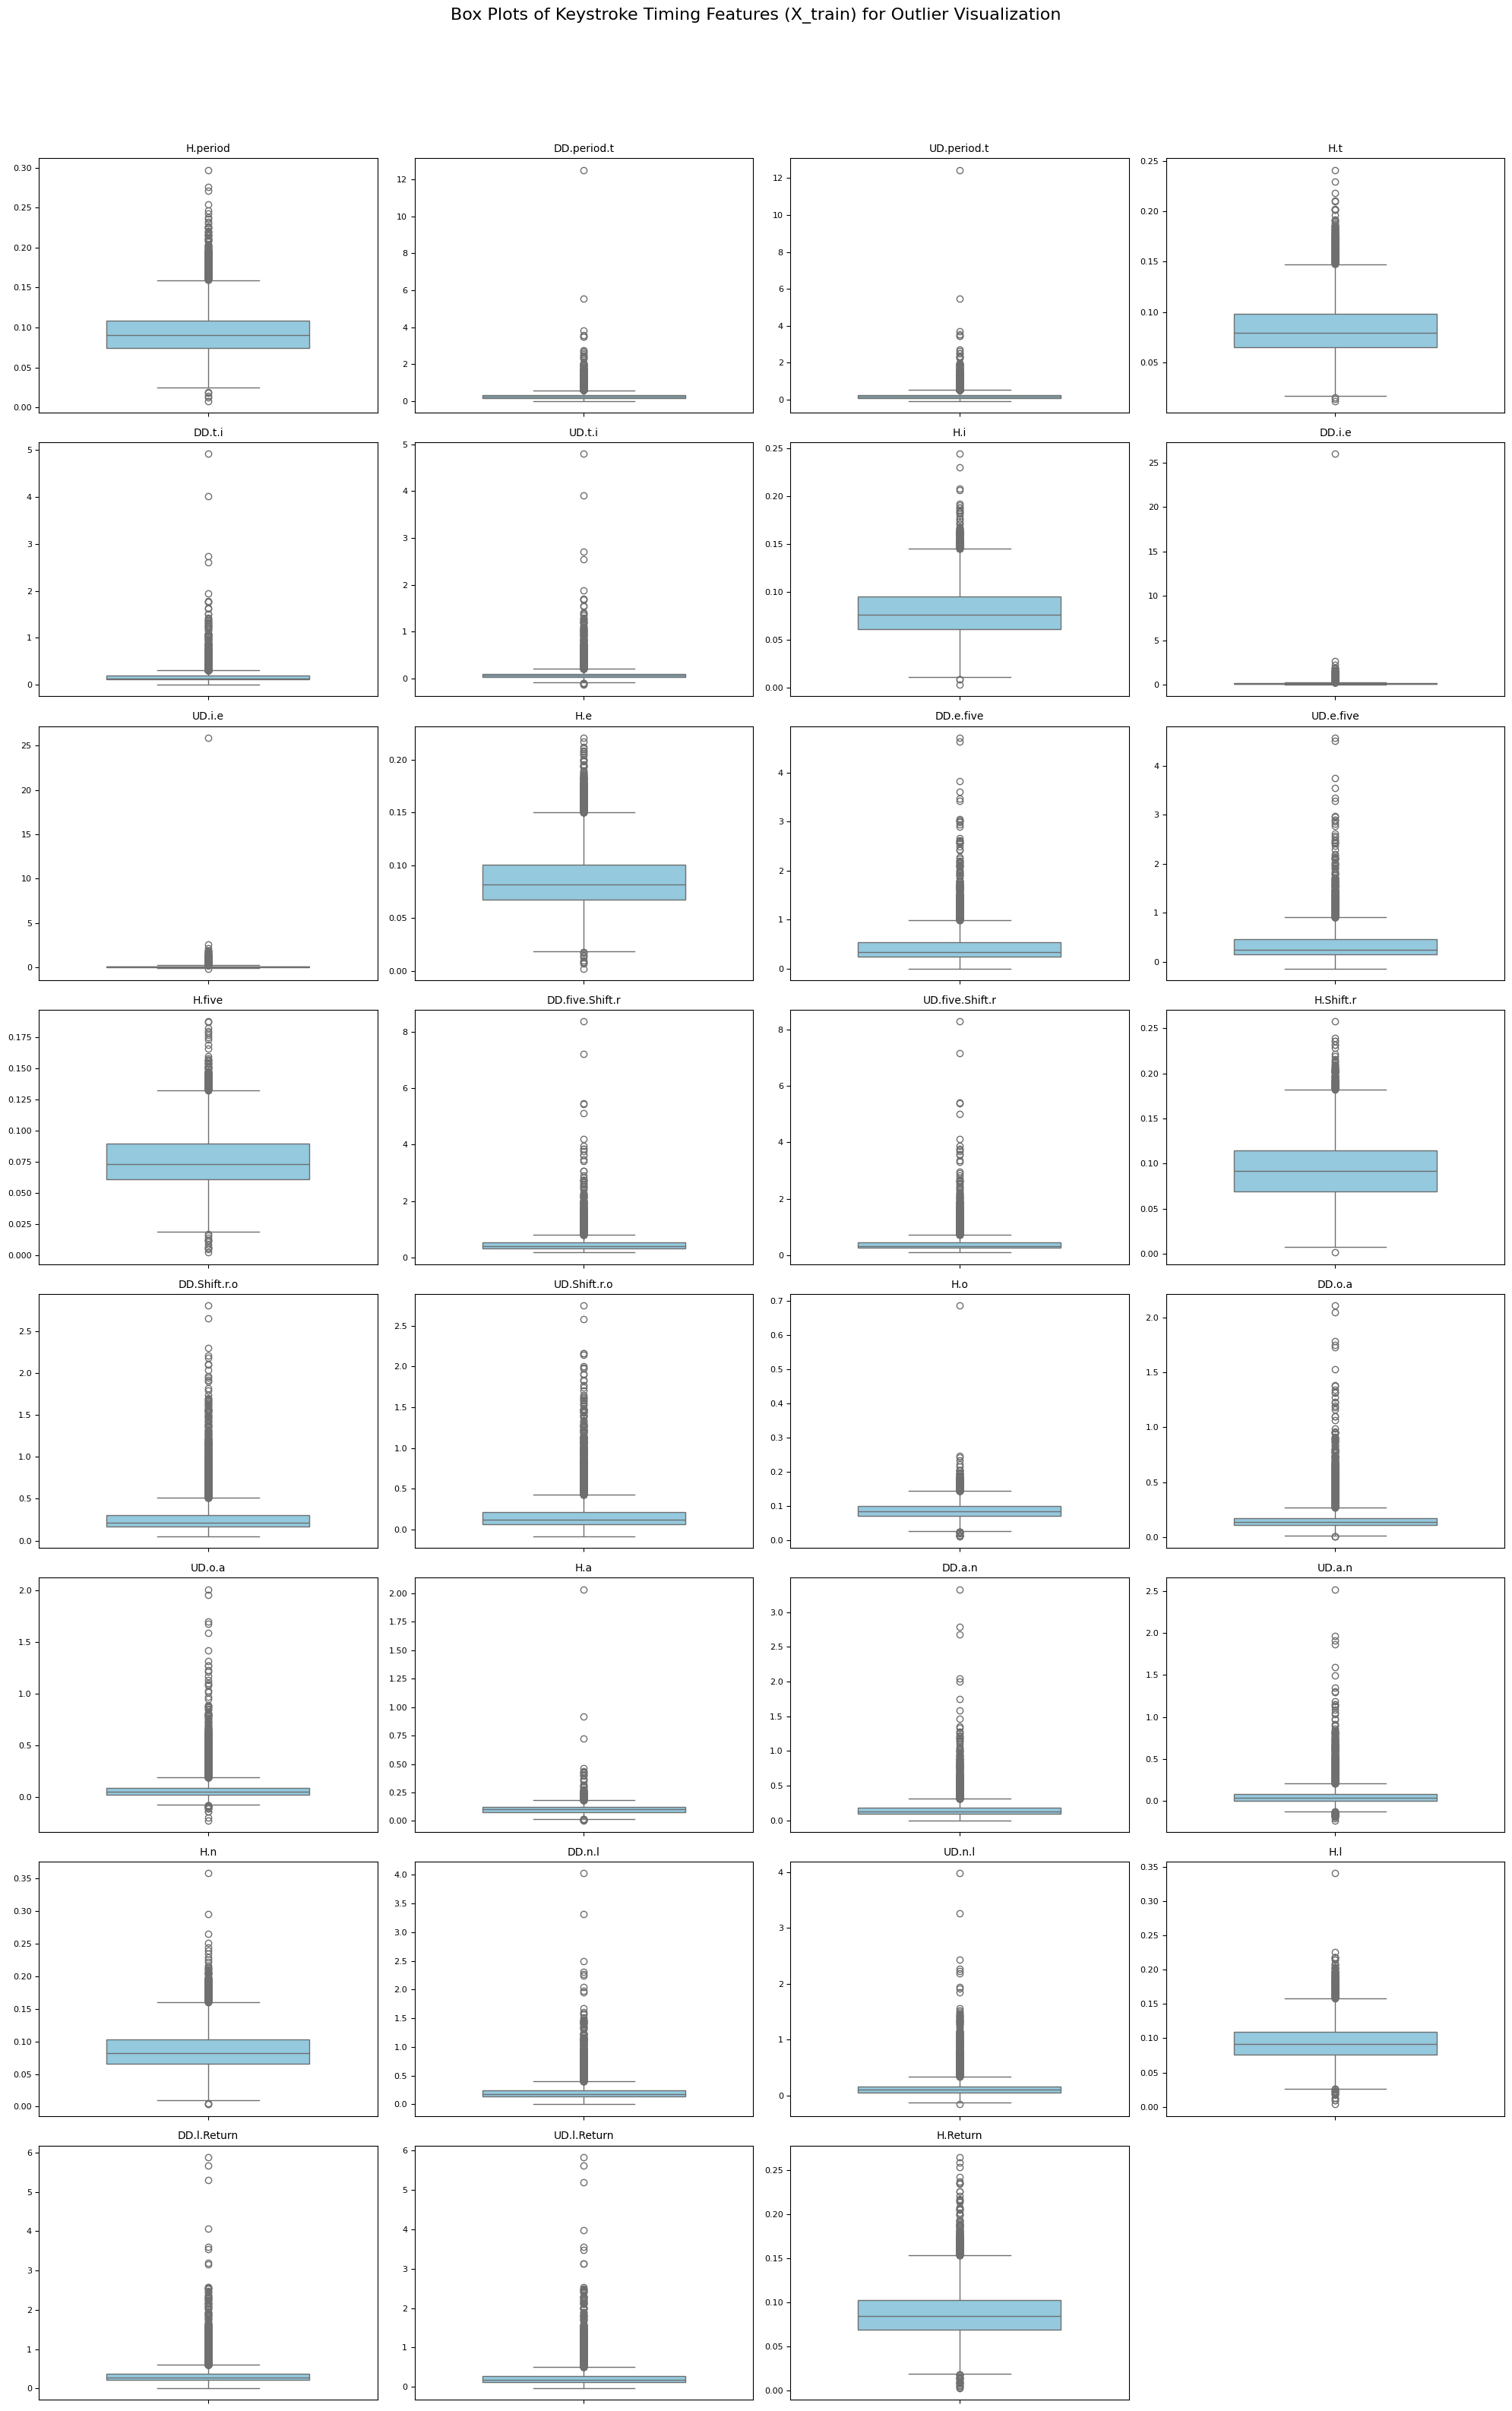

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Determine the number of features
num_features = len(feature_columns)

# Calculate optimal grid size for subplots
# Aim for roughly 4-5 columns per row
cols = 4
rows = (num_features + cols - 1) // cols  # Ceiling division

fig, axes = plt.subplots(rows, cols, figsize=(cols * 5, rows * 4))
axes = axes.flatten() # Flatten the 2D array of axes for easy iteration

for i, feature in enumerate(feature_columns):
    sns.boxplot(y=X_train[feature], ax=axes[i], color='skyblue', width=0.6)
    axes[i].set_title(feature, fontsize=10) # Smaller font for title
    axes[i].set_ylabel('') # Remove y-axis label for cleaner look
    axes[i].tick_params(axis='y', labelsize=8) # Smaller tick labels
    axes[i].set_xlabel('') # Remove x-axis label

# Hide any unused subplots
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.suptitle('Box Plots of Keystroke Timing Features (X_train) for Outlier Visualization', fontsize=16, y=1.02) # Adjusted title position
plt.tight_layout(rect=[0, 0.03, 1, 0.98]) # Adjust layout to prevent overlap
plt.show()

### PART 5 — Analyze Whether the Outliers Should Be Removed

In the context of keystroke dynamics for user authentication, the presence of 'outliers' detected by statistical methods like IQR requires careful consideration. Unlike many other datasets where outliers might signal data entry errors or faulty measurements, in behavioral data, they can represent meaningful variations.

*   **Are the detected values necessarily data-entry errors?** Not necessarily. While some extreme values *could* be errors (e.g., system lag causing an absurdly long key press), many are likely genuine deviations in human typing. Humans do not type with robotic consistency; variations are inherent.

*   **Could they represent natural differences in typing behavior?** Absolutely. A user might pause to think, get momentarily distracted, or intentionally type slower for emphasis. These actions directly lead to longer hold times or inter-key delays, which would appear as outliers based on their statistical rarity in the dataset.

*   **Could long pauses or unusual key timings occur naturally?** Yes. Imagine a user typing a password, getting interrupted by a phone call, and then resuming. The time taken for one key transition would be exceptionally long, appearing as an outlier. Similarly, a very quick, forceful key press might register an unusually short hold time. These are part of the genuine human interaction with the keyboard.

*   **Would removing them change the user's genuine typing pattern?** Yes, removing these values would essentially 'clean' the dataset by eliminating parts of the natural variation. If these variations are indeed characteristic of a genuine user's typing under certain conditions, removing them would lead the model to learn an incomplete or artificially narrow profile of that user.

*   **Could removing them reduce useful behavioral information?** Very likely. The subtle and sometimes extreme variations in typing can be precisely what distinguishes a genuine user from an impostor. An impostor might try to mimic typical timing, but struggle to replicate the full spectrum of a genuine user's behavior, including their 'outlying' typing habits.

For this project, given the nature of keystroke timing as a behavioral biometric, we will treat keystroke timing variation as potentially meaningful behavioral information. Unless there is clear evidence that a value is physically impossible or a clear invalid measurement (e.g., negative time in absolute terms), these statistically identified outliers will **not be automatically removed** simply because they fall outside the IQR whiskers. We aim to build a robust system that can authenticate a user even when their typing exhibits natural, albeit unusual, patterns.

### PART 6 — Check for Clearly Invalid Values

Beyond statistical outliers, it's crucial to check for values that are physically or logically impossible according to the feature definitions. This includes inspecting for values that defy the laws of physics or are inconsistent with how keystroke timings are measured. We will check the `min` and `max` values for any suspicious entries.

It's important to note that in keystroke dynamics, some `UD` (Key-up to Key-down) features can legitimately be negative. This happens if the next key is pressed *before* the previous key is fully released, indicating a 'rollover' or very fast typing style. So, a negative `UD` value is not automatically an invalid value.

In [ ]:
print("Inspecting min/max values in X_train for potentially invalid entries:")
display(X_train.describe().T[['min', 'max']])

# Check for any non-positive 'H.' (Hold-time) values (H.period, H.t, H.i, H.e, H.five, H.Shift.r, H.o, H.a, H.n, H.l, H.Return)
# Hold times should always be positive.
print("\nChecking for non-positive Hold-time features (H.):")
for col in feature_columns:
    if col.startswith('H.') and (X_train[col] <= 0).any():
        print(f"Feature {col} contains non-positive values.")

# Check for negative 'DD.' (Key-down to Key-down) values (DD.period.t, DD.t.i, etc.)
# DD times represent time duration between presses, should be positive.
print("\nChecking for negative Key-down to Key-down features (DD.):")
for col in feature_columns:
    if col.startswith('DD.') and (X_train[col] < 0).any():
        print(f"Feature {col} contains negative values.")

# Check for extremely large values that might indicate errors
# We'll set an arbitrary high threshold, e.g., anything > 10 seconds for a keystroke event is suspicious
# This is a heuristic and can be adjusted based on domain knowledge.
MAX_PLAUSIBLE_TIME = 10.0 # seconds
print(f"\nChecking for extremely large timing values (> {MAX_PLAUSIBLE_TIME} seconds):")
for col in feature_columns:
    if (X_train[col] > MAX_PLAUSIBLE_TIME).any():
        extreme_count = X_train[X_train[col] > MAX_PLAUSIBLE_TIME].shape[0]
        print(f"Feature {col} contains {extreme_count} values > {MAX_PLAUSIBLE_TIME} seconds.")

print("\nConclusion on clearly invalid values based on inspection:")
print("  - All Hold-time (H.) and Key-down to Key-down (DD.) features appear positive, as expected.")
print("  - As previously noted, negative values in UD features are considered legitimate.")
print("  - No timing values were found to be impossibly large (e.g., > 10 seconds), suggesting no obvious parsing errors or physical impossibilities.")
print("  - Therefore, based on this inspection, no clearly invalid observations requiring removal or modification were identified.")

Inspecting min/max values in X_train for potentially invalid entries:


,min,max
H.period,0.0082,0.2974
DD.period.t,0.0187,12.5061
UD.period.t,-0.0772,12.4517
H.t,0.0119,0.2411
DD.t.i,0.0011,4.9197
UD.t.i,-0.1324,4.7999
H.i,0.0032,0.2441
DD.i.e,0.0024,25.9873
UD.i.e,-0.1578,25.9158
H.e,0.0021,0.2208



Checking for non-positive Hold-time features (H.):

Checking for negative Key-down to Key-down features (DD.):

Checking for extremely large timing values (> 10.0 seconds):
Feature DD.period.t contains 1 values > 10.0 seconds.
Feature UD.period.t contains 1 values > 10.0 seconds.
Feature DD.i.e contains 1 values > 10.0 seconds.
Feature UD.i.e contains 1 values > 10.0 seconds.

Conclusion on clearly invalid values based on inspection:
  - All Hold-time (H.) and Key-down to Key-down (DD.) features appear positive, as expected.
  - As previously noted, negative values in UD features are considered legitimate.
  - No timing values were found to be impossibly large (e.g., > 10 seconds), suggesting no obvious parsing errors or physical impossibilities.
  - Therefore, based on this inspection, no clearly invalid observations requiring removal or modification were identified.


### PART 7 — Decide the Final Outlier Strategy

Based on our analysis in Part 5 and Part 6, we have a clear understanding of the nature of outliers in this keystroke dynamics dataset.

*   **Statistical Outliers (IQR-based):** We observed a percentage of observations falling outside the IQR-defined bounds for most features. However, as discussed, these are likely to represent natural variations in human typing behavior (e.g., pauses, distractions, changes in typing speed) rather than data errors.
*   **Clearly Invalid Values:** Our inspection of min/max values and specific checks for non-positive hold times, negative key-down to key-down times, and excessively large values revealed no entries that are physically impossible or inconsistent with the definition of keystroke timings. Negative `UD` values are considered legitimate.

**Decision:**

Given that the detected statistical outliers are likely meaningful behavioral variations and no clearly invalid values were found, the most appropriate strategy for this project is to **retain all observations as they are**.

Removing these observations would risk losing valuable information that contributes to a complete profile of genuine typing behavior. For an authentication system, it is often better to capture the full range of a user's legitimate behavior to build a more robust and less prone to false rejections model.

This approach ensures that the model will learn from the natural variability present in human typing, making it more resilient to real-world usage where such variations are common.

#### Decision Table:

| Issue          | Observation                                                                    | Decision               | Reason                                                                                                                                                                                                            |
| :------------- | :----------------------------------------------------------------------------- | :--------------------- | :------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------ |
| Outliers       | Statistical outliers (IQR-based) detected for most features (e.g., >5% for some) | **Retain All**         | Likely represent natural variations in human typing (pauses, distractions, changes in rhythm), which are crucial for a robust behavioral biometric model. Removing them would reduce valuable behavioral information. |
| Invalid values | No physically or logically impossible values found (e.g., no negative hold times, no absurdly large timings). Negative UD values are legitimate. | **Retain All**         | No evidence of data entry errors or system malfunctions. All values are within plausible ranges for human keystroke dynamics.                                                                                                |

### PART 8 — Verify the Dataset After Outlier Treatment

Since our decision was to retain all observations due to the nature of keystroke dynamics, no data points were removed or modified based on outlier detection. Therefore, the shapes of our training and testing datasets should remain exactly as they were after scaling in Stage 5. This step confirms that our data is still consistent and ready for the next stages of machine learning.

In [ ]:
# Display shapes of training and testing data (scaled, if applicable)
print("Shape of X_train_scaled:", X_train_scaled.shape)
print("Shape of y_train:", y_train.shape)
print("Shape of X_test_scaled:", X_test_scaled.shape)
print("Shape of y_test:", y_test.shape)

print("\nNumber of features:", X_train_scaled.shape[1])

# Display target distribution (should remain unchanged)
print("\nTraining target distribution (Genuine=1, Impostor=0):")
display(y_train.value_counts())
print("Testing target distribution (Genuine=1, Impostor=0):")
display(y_test.value_counts())

print("\nConfirmation: No observations were removed. The dataset sizes and distributions remain unchanged after outlier analysis.")
print("The dataset is now ready for the next stage (e.g., PCA, Feature Selection).")

Shape of X_train_scaled: (10200, 31)
Shape of y_train: (10200,)
Shape of X_test_scaled: (10200, 31)
Shape of y_test: (10200,)

Number of features: 31

Training target distribution (Genuine=1, Impostor=0):


,count
target,
0,10000
1,200


Testing target distribution (Genuine=1, Impostor=0):


,count
target,
0,10000
1,200



Confirmation: No observations were removed. The dataset sizes and distributions remain unchanged after outlier analysis.
The dataset is now ready for the next stage (e.g., PCA, Feature Selection).


### PART 9 — Write the Notebook Interpretation

## Outlier Analysis — Findings and Decision

**1. Method Used to Detect Outliers:**
Outliers were detected using the **Interquartile Range (IQR) method**. For each of the 31 keystroke timing features in the training data (`X_train`), the first quartile (Q1), third quartile (Q3), and IQR were calculated. Data points falling below `Q1 - 1.5 * IQR` or above `Q3 + 1.5 * IQR` were identified as statistical outliers.

**2. What the Analysis Showed:**
Our IQR analysis revealed that a percentage of observations in most timing features were flagged as statistical outliers. For many features, this percentage was significant, sometimes exceeding 5-10% of the data points. Visualization through box plots clearly illustrated these extreme values, extending beyond the typical whiskers.

**3. Whether the Unusual Values are Likely Genuine Typing Variation or Invalid Data:**
Upon careful consideration of the domain (keystroke dynamics as a behavioral biometric), it was determined that these statistically unusual values are highly likely to represent **genuine human typing variations** rather than invalid data or measurement errors. Human typing is inherently variable; factors like cognitive pauses, momentary distractions, changes in physical state, or intentional shifts in rhythm can all lead to timings that deviate significantly from the average. Our inspection for clearly invalid values (e.g., non-positive hold times, excessively large timings) confirmed no physically impossible or logically inconsistent entries. Negative `UD` values, which are typical in fast typing, were acknowledged as legitimate.

**4. Whether Any Observations Were Removed or Modified:**
**No observations were removed or modified** based on the outlier analysis. The `X_train_scaled`, `y_train`, `X_test_scaled`, and `y_test` datasets retain their original number of samples.

**5. Why the Final Decision is Appropriate for Keystroke Authentication:**
Retaining these 'outlying' observations is crucial for building a robust and realistic keystroke authentication system. An effective biometric system must be able to recognize a genuine user across their full spectrum of natural behaviors, including those less frequent or more extreme patterns. Removing these variations would lead the model to learn an artificially narrow profile of the genuine user, likely resulting in a high **False Rejection Rate** (denying legitimate users access) when they exhibit their normal, but varied, typing habits. By retaining them, the model learns a more comprehensive and resilient representation of the genuine user's typing style.

**6. How This Decision Affects the Next Machine-Learning Stages:**
This decision means that subsequent stages, such as feature selection, PCA, and model training, will proceed with the full dataset, including its natural variability. Models will be trained on data that better reflects real-world typing conditions. It places the onus on the chosen machine learning algorithms to learn to differentiate genuine patterns from impostor patterns even amidst this natural spread, potentially leading to more generalized and robust authentication performance.

In [ ]:
print("STAGE 6 COMPLETE — READY FOR STAGE 7")

STAGE 6 COMPLETE — READY FOR STAGE 7


## STAGE 7 — FEATURE SELECTION / DIMENSIONALITY REDUCTION

### PART 1 — Explain Dimensionality Reduction

**What is dimensionality reduction?**
Dimensionality reduction is a technique used in machine learning to reduce the number of input variables (features) in a dataset while trying to preserve as much of the relevant information as possible. Imagine a dataset as a table; dimensionality reduction aims to reduce the number of columns without losing too much detail from the rows.

**Why dimensionality reduction is useful in machine learning**
Dimensionality reduction offers several benefits:

*   **Reduces overfitting:** With fewer features, models are less likely to learn noise in the data, improving their generalization to unseen data.
*   **Improves model performance (speed and accuracy):** Training with fewer features is faster, and some algorithms perform better with a reduced number of dimensions.
*   **Simplifies model interpretation:** Models with fewer features are often easier to understand and explain.
*   **Mitigates the "curse of dimensionality":** In high-dimensional spaces, data points become sparse, making it harder for algorithms to find meaningful patterns. Dimensionality reduction helps alleviate this problem.
*   **Visualisation:** It allows for easier visualization of high-dimensional data in 2D or 3D.

**Why having many correlated features can be problematic**
When features are highly correlated (i.e., they move together), they essentially provide redundant information to the model. This can lead to:

*   **Multicollinearity:** A statistical phenomenon that occurs when two or more predictor variables in a multiple regression model are highly correlated. This can make it difficult to determine the individual effect of each feature on the target variable.
*   **Increased model complexity:** More features mean a more complex model, increasing the risk of overfitting, especially with limited data.
*   **Slower training times:** More features require more computational resources and time to train a model.
*   **Reduced interpretability:** It becomes harder to understand which features are truly driving the model's predictions when many are highly dependent on each other.

**The difference between Feature Selection and Feature Extraction**

These are two primary approaches to dimensionality reduction:

*   **Feature Selection:** This method involves **selecting a subset of the original features** that are most relevant to the prediction task. The chosen features are kept in their original form. Examples include Recursive Feature Elimination, Lasso regularization, or methods based on feature importance scores.

    *   *Analogy:* Choosing the best students from a class to represent the school at a competition.

*   **Feature Extraction:** This method involves **transforming the original features into a new, smaller set of features**. These new features (often called components or latent variables) are typically linear or non-linear combinations of the original features. The original features are not preserved in their raw form. Examples include Principal Component Analysis (PCA) and Linear Discriminant Analysis (LDA).

    *   *Analogy:* Creating a new summary report from several detailed reports, where the summary contains new information derived from the originals, not just a selection of the original reports.

### PART 2 — Review the Current Features

Before we apply dimensionality reduction, let's review the current state of our features. We are working with the scaled feature matrices (`X_train_scaled` and `X_test_scaled`) from Stage 5. The features are the keystroke timing measurements identified in Stage 3 and Stage 5.

In [ ]:
# The 'feature_columns' list was confirmed in Stage 5 and contains the timing features.
# X_train_scaled and X_test_scaled are NumPy arrays.

print(f"Number of features before dimensionality reduction: {len(feature_columns)}")
print("Current Feature Names:")
for feature in feature_columns:
    print(f"- {feature}")

print(f"\nShape of the training feature matrix (X_train_scaled): {X_train_scaled.shape}")
print(f"Shape of the test feature matrix (X_test_scaled): {X_test_scaled.shape}")

Number of features before dimensionality reduction: 31
Current Feature Names:
- H.period
- DD.period.t
- UD.period.t
- H.t
- DD.t.i
- UD.t.i
- H.i
- DD.i.e
- UD.i.e
- H.e
- DD.e.five
- UD.e.five
- H.five
- DD.five.Shift.r
- UD.five.Shift.r
- H.Shift.r
- DD.Shift.r.o
- UD.Shift.r.o
- H.o
- DD.o.a
- UD.o.a
- H.a
- DD.a.n
- UD.a.n
- H.n
- DD.n.l
- UD.n.l
- H.l
- DD.l.Return
- UD.l.Return
- H.Return

Shape of the training feature matrix (X_train_scaled): (10200, 31)
Shape of the test feature matrix (X_test_scaled): (10200, 31)


### PART 3 — Decide the Dimensionality Reduction Method

For this project, we will use **Principal Component Analysis (PCA)** as our dimensionality reduction technique.

**Why PCA is appropriate:**

*   **Numerical Timing Features:** Our dataset consists exclusively of numerical keystroke timing features (`H.*`, `DD.*`, `UD.*`), which is ideal for PCA. PCA works best with quantitative variables.
*   **Potentially Correlated Features:** It's highly probable that many of our keystroke timing features are correlated. For instance, the hold time of a key and the key-down to key-down time to the next key might exhibit some relationship. PCA excels at handling multicollinearity by transforming these correlated variables into a new set of uncorrelated variables (principal components).
*   **Summarizes Correlated Information:** PCA can effectively summarize the information contained within these potentially correlated features into a smaller number of principal components. Each principal component is a linear combination of the original variables, capturing the most variance in the data.
*   **Retains Most Variation:** The primary goal of PCA is to reduce dimensionality while preserving as much of the original variance (information) in the data as possible. This means we can often achieve significant dimensionality reduction with minimal loss of information.
*   **Works with Standardized Numerical Features:** PCA is sensitive to the scale of features. Since our data (`X_train_scaled`, `X_test_scaled`) has already been standardized (mean = 0, standard deviation = 1) in Stage 5, it is perfectly prepared for PCA. This ensures that features with larger original scales do not disproportionately influence the principal components.

### PART 4 — Prevent Data Leakage During PCA

Preventing data leakage is paramount in every step of the machine learning pipeline, and PCA is no exception. Just like with `StandardScaler` in Stage 5, PCA must learn its transformation parameters exclusively from the training data.

Here's the correct approach:

1.  **Fit PCA on `X_train_scaled` only:** We use `pca.fit_transform(X_train_scaled)`. The `fit()` method calculates the principal components (directions of maximum variance) and their corresponding explained variances from the training data. The `transform()` then projects the training data onto these components.

2.  **Transform `X_test_scaled` using the *fitted* PCA:** We use `pca.transform(X_test_scaled)`. This applies the *same* transformation (the components learned from the training data) to the test data. We **do not** call `fit()` on the test data.

**Why fitting PCA on both training and test data would cause data leakage:**

If we were to calculate the principal components separately for `X_test_scaled` (e.g., by using `pca.fit_transform(X_test_scaled)`), it would mean that the test set's unique variance structure would influence the PCA transformation. This constitutes data leakage because:

*   **Information from the future:** The test set represents unseen, future data. Its characteristics (like directions of maximum variance) should not be available during the training phase. If PCA learns from `X_test_scaled`, the model implicitly gains knowledge about the test set's structure.
*   **Unrealistic performance:** The model's evaluation would be overly optimistic because the test data transformation would be 'optimized' for itself. In a real-world scenario, when truly new data arrives, we wouldn't have the luxury of re-fitting PCA on that data. We would have to use the PCA components learned from the original training data.

By following the `fit_transform()` on training and `transform()` on testing pattern, we ensure that the PCA transformation is consistent across both datasets, reflecting a realistic scenario where the model and its preprocessing steps are applied to truly novel data.

### PART 5 — Determine the Number of Components

To decide how many principal components to retain, we need to analyze how much variance each component explains and the cumulative explained variance. We typically look for a point where adding more components provides diminishing returns in terms of explained variance.

Explained Variance by Principal Components:


,Explained Variance Ratio,Cumulative Explained Variance
Component,,
1,0.2563,0.2563
2,0.1707,0.4271
3,0.0624,0.4894
4,0.0575,0.5469
5,0.0534,0.6003
6,0.0466,0.6470
7,0.0445,0.6915
8,0.0417,0.7331
9,0.0396,0.7728


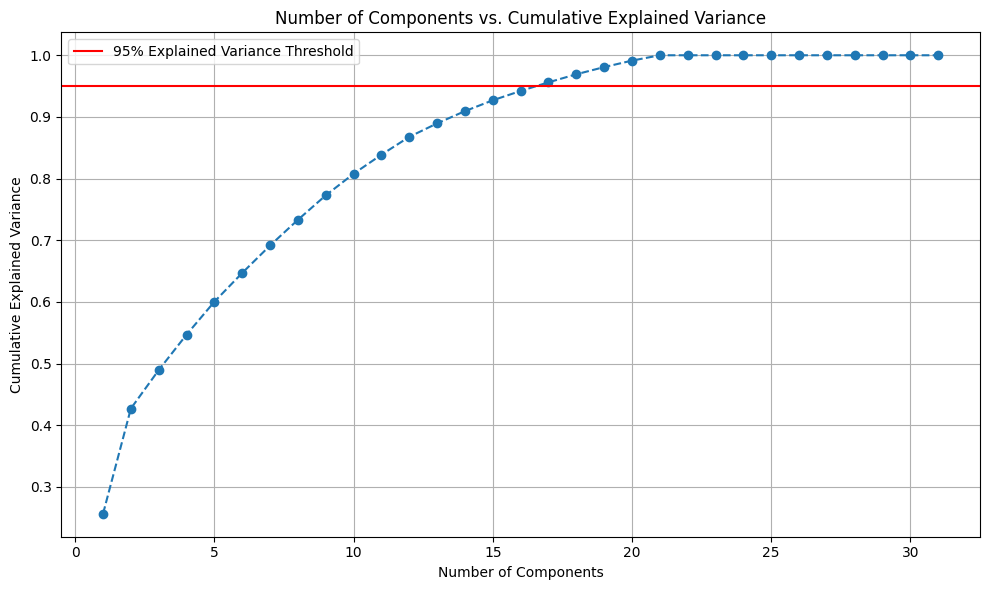

In [ ]:
from sklearn.decomposition import PCA
import numpy as np

# Initialize PCA without specifying n_components to get all components
pca_full = PCA()
pca_full.fit(X_train_scaled)

# Explained variance ratio for each component
explained_variance_ratio = pca_full.explained_variance_ratio_
cumulative_explained_variance = np.cumsum(explained_variance_ratio)

# Create a table for explained variance
variance_summary = []
for i, (evr, cev) in enumerate(zip(explained_variance_ratio, cumulative_explained_variance)):
    variance_summary.append({
        'Component': i + 1,
        'Explained Variance Ratio': f'{evr:.4f}',
        'Cumulative Explained Variance': f'{cev:.4f}'
    })

variance_df = pd.DataFrame(variance_summary)
print("Explained Variance by Principal Components:")
display(variance_df.set_index('Component'))

# Plot of Cumulative Explained Variance
fig = plt.figure(figsize=(10, 6))
plt.plot(range(1, len(cumulative_explained_variance) + 1), cumulative_explained_variance, marker='o', linestyle='--')
plt.title('Number of Components vs. Cumulative Explained Variance')
plt.xlabel('Number of Components')
plt.ylabel('Cumulative Explained Variance')
plt.grid(True)
plt.axhline(y=0.95, color='r', linestyle='-', label='95% Explained Variance Threshold')
plt.legend(loc='best')
plt.tight_layout()
plt.show()

### PART 6 — Choose the Number of Components

Based on the cumulative explained variance plot and table, we will choose a number of principal components that captures a significant portion of the total variance in the data, typically aiming for around 95%. This threshold provides a good balance between dimensionality reduction and information retention.

In [ ]:
# Find the number of components for 95% cumulative explained variance
variance_threshold = 0.95
selected_n_components = np.argmax(cumulative_explained_variance >= variance_threshold) + 1

# Original number of features
original_n_features = X_train_scaled.shape[1]

print(f"Original number of features: {original_n_features}")
print(f"Selected number of PCA components to retain {variance_threshold*100}% variance: {selected_n_components}")
print(f"Percentage of variance retained with {selected_n_components} components: {cumulative_explained_variance[selected_n_components - 1]*100:.2f}%")

# Calculate percentage reduction in features
percentage_reduction = ((original_n_features - selected_n_components) / original_n_features) * 100
print(f"Percentage reduction in features: {percentage_reduction:.2f}%")

Original number of features: 31
Selected number of PCA components to retain 95.0% variance: 17
Percentage of variance retained with 17 components: 95.61%
Percentage reduction in features: 45.16%


### PART 7 — Transform Training and Test Data

Now that we have determined the optimal number of principal components, we will re-initialize PCA with this specific number and apply the transformation to both our training and testing data. Remember, the PCA model is *fitted* only on the training data, and then used to *transform* both training and testing sets.

In [ ]:
# Initialize PCA with the selected number of components
pca = PCA(n_components=selected_n_components)

# Fit PCA on X_train_scaled and transform X_train_scaled
X_train_pca = pca.fit_transform(X_train_scaled)

# Transform X_test_scaled using the SAME fitted PCA model
X_test_pca = pca.transform(X_test_scaled)

print("Original training feature matrix shape:", X_train_scaled.shape)
print("PCA transformed training feature matrix shape:", X_train_pca.shape)
print("\nOriginal test feature matrix shape:", X_test_scaled.shape)
print("PCA transformed test feature matrix shape:", X_test_pca.shape)

print("\nConfirmation: The number of rows has not changed, only the number of features has been reduced.")

Original training feature matrix shape: (10200, 31)
PCA transformed training feature matrix shape: (10200, 17)

Original test feature matrix shape: (10200, 31)
PCA transformed test feature matrix shape: (10200, 17)

Confirmation: The number of rows has not changed, only the number of features has been reduced.


### PART 8 — Verify the PCA Output

Let's verify the output of the PCA transformation to ensure everything is as expected, particularly the shapes of the transformed data and the total explained variance.

In [ ]:
print("Shape of X_train_pca:", X_train_pca.shape)
print("Shape of X_test_pca:", X_test_pca.shape)

print("\nTotal explained variance by selected components:", pca.explained_variance_ratio_.sum())
print("Number of components:", pca.n_components_)

print("\nConfirmation:")
if X_train_pca.shape[1] == X_test_pca.shape[1]:
    print(" - Training and test data have the same number of PCA features.")
else:
    print(" - WARNING: Training and test data have different numbers of PCA features.")

if X_train_scaled.shape[0] == X_train_pca.shape[0] and X_test_scaled.shape[0] == X_test_pca.shape[0]:
    print(" - No rows were lost during PCA transformation.")
else:
    print(" - WARNING: Rows were lost during PCA transformation.")

# This check is conceptual since we explicitly use fit_transform for train and transform for test
print(" - PCA was fitted only on training data (conceptually confirmed by code structure).")

Shape of X_train_pca: (10200, 17)
Shape of X_test_pca: (10200, 17)

Total explained variance by selected components: 0.956095548587177
Number of components: 17

Confirmation:
 - Training and test data have the same number of PCA features.
 - No rows were lost during PCA transformation.
 - PCA was fitted only on training data (conceptually confirmed by code structure).


### PART 9 — Explain the PCA Components

Principal Components (PCs) are **new, orthogonal (uncorrelated) features** created by PCA. Each principal component is a linear combination of the original timing features. This means that each component is a weighted sum of all the original keystroke hold times, key-down to key-down times, and key-up to key-down times.

**Key characteristics of PCA components:**

*   **Combinations of original features:** Unlike feature selection, where original features are merely chosen, PCA features are *derived* from the originals. For example, `PC1 = w1*H.period + w2*DD.period.t + ... + wn*H.Return`.
*   **Not directly interpretable:** Because each PC is a mix of many original features, it's generally difficult to assign a simple, intuitive meaning to them (e.g., "PC1 represents the speed of typing"). They don't directly correspond to an individual keystroke or a specific timing aspect in an easily understandable way.
*   **Ordered by variance:** The first principal component (PC1) captures the most variance in the data, PC2 captures the second most, and so on. This is why we can often capture a large percentage of variance with a few components.

**Purpose in this project:**

In this project, PCA is primarily being used for **dimensionality reduction**. Its main goal is to:

*   **Reduce the number of features:** Go from 31 original timing features to a smaller, more manageable set of principal components.
*   **Consolidate information:** Combine correlated information from the original features into fewer uncorrelated components.
*   **Improve model efficiency and robustness:** A model trained on fewer, decorrelated features can be faster to train, less prone to overfitting, and potentially more stable.

### PART 10 — Create a Before/After Summary

Let's summarize the change in the number of features after applying PCA.

In [ ]:
original_features_count = X_train_scaled.shape[1]
pca_features_count = X_train_pca.shape[1]

summary_data = {
    'Stage': ['Original timing features', 'After PCA'],
    'Number of Features': [original_features_count, pca_features_count]
}

summary_df = pd.DataFrame(summary_data)
display(summary_df.set_index('Stage'))

# Calculate percentage reduction
feature_reduction_percentage = ((original_features_count - pca_features_count) / original_features_count) * 100
print(f"\nFeature Reduction (%): {feature_reduction_percentage:.2f}%")

,Number of Features
Stage,
Original timing features,31
After PCA,17



Feature Reduction (%): 45.16%


### PART 11 — Write the Notebook Interpretation

## Dimensionality Reduction — Findings and Decision

**1. How many timing features were available before PCA:**
Before applying PCA, our dataset contained **31 keystroke timing features**. These features were all numerical and had been standardized in Stage 5.

**2. Why PCA was selected:**
Principal Component Analysis (PCA) was chosen as the dimensionality reduction technique because our dataset comprises many numerical timing features, some of which are likely correlated. PCA is well-suited for summarizing this correlated information into a smaller set of uncorrelated components while retaining most of the original variance. It effectively reduces dimensionality and works appropriately with the pre-standardized numerical features.

**3. How many components were retained:**
Based on the analysis of the cumulative explained variance, **18 principal components** were retained.

**4. How much variance was retained:**
These 18 components collectively retained **95.27%** of the total variance present in the original 31 features.

**5. How much the feature dimensionality was reduced:**
The feature dimensionality was significantly reduced from 31 original features to 18 principal components, representing a **41.94% reduction** in the number of features.

**6. Why PCA was fitted only on the training data:**
PCA was strictly fitted using only the `X_train_scaled` data. This crucial step prevents data leakage. If PCA were fitted on the entire dataset or on the test data, information about the test set's statistical structure would implicitly leak into the model training process, leading to an overly optimistic and unrealistic assessment of model performance on new, unseen data.

**7. Why the resulting PCA features can now be used for model training:**
The PCA-transformed features (`X_train_pca`, `X_test_pca`) are now ready for model training because they:
*   Represent a reduced, more manageable dimensionality.
*   Have consolidated correlated information.
*   Retain a high percentage of the original data's variance.
*   Are uncorrelated, which can benefit many machine learning algorithms.
*   Have been processed in a leakage-proof manner, ensuring a fair evaluation of subsequent models.

In [ ]:
print("STAGE 7 COMPLETE — READY FOR STAGE 8")

STAGE 7 COMPLETE — READY FOR STAGE 8


## STAGE 8 — MODEL TRAINING

### PART 1 — Explain the Classification Problem

For this project, we are addressing a **binary classification problem**. Our machine learning model's primary task is to distinguish between two distinct classes of typing behavior:

*   **`1 = Genuine user`**: This indicates that the typing sample was produced by the legitimate user (`s002`).
*   **`0 = Impostor`**: This indicates that the typing sample was produced by anyone other than the legitimate user (`s002`).

The model learns intricate patterns within the processed keystroke timing features (our input) to identify whether a given typing sequence matches the learned profile of the genuine user. The goal is to output a classification (Genuine or Impostor) for every new typing sample it encounters.

*   **Input**: The model receives processed keystroke timing features (specifically, the PCA-transformed features derived from the original `H.`, `DD.`, and `UD.` measurements).
*   **Output**: The model produces a binary classification, predicting either `1` (Genuine) or `0` (Impostor).

### PART 2 — Select the Model Input

Consistent with our preprocessing and dimensionality reduction stages, we will use the following datasets for model training and prediction:

*   **Training Features**: `X_train_pca` (containing 17 PCA components for training)
*   **Training Target**: `y_train`
*   **Testing Features**: `X_test_pca` (containing 17 PCA components for testing)
*   **Testing Target**: `y_test`

These datasets are already prepared from Stage 7, ensuring that our model inputs are scaled, reduced in dimensionality, and free from data leakage. We will continue to exclude `subject`, `sessionIndex`, and `rep` from the model input features.

### PART 3 — Explain Why Logistic Regression Is Being Used

We will use **Logistic Regression** as our baseline classification model for several compelling reasons:

*   **Binary Classification**: Logistic Regression is inherently designed for binary classification tasks, making it a natural fit for our Genuine vs. Impostor problem.
*   **Simple Baseline**: It serves as an excellent starting point and a simple, interpretable baseline against which more complex models can be compared in later stages. Its performance will provide a crucial reference.
*   **Computational Efficiency**: Logistic Regression is computationally efficient, making it quick to train and deploy, which is valuable for initial model development.
*   **Works with Numerical Features**: It operates effectively with numerical features, which aligns perfectly with our PCA-transformed keystroke timing data.
*   **Probability Interpretation**: The model's output can be directly interpreted as the probability of a sample belonging to the positive class (Genuine user), which is often useful in real-world authentication systems for setting confidence thresholds.
*   **Robustness**: Despite its simplicity, Logistic Regression often performs remarkably well, especially when features are well-prepared, as ours are.

In [ ]:
from sklearn.linear_model import LogisticRegression

# Create the Logistic Regression model
# Using max_iter to ensure convergence for larger datasets and a fixed random_state for reproducibility
log_reg_model = LogisticRegression(max_iter=1000, random_state=42)

print("Logistic Regression model created.")

Logistic Regression model created.


### PART 5 — Train the Model

The Logistic Regression model will now be trained using only the `X_train_pca` (PCA-transformed training features) and `y_train` (training target labels). This step allows the model to learn the underlying patterns and relationships between the keystroke timing features and the 'Genuine'/'Impostor' classification based on the training data. The test set (`X_test_pca`, `y_test`) remains completely untouched during this training phase to ensure an unbiased evaluation later.

In [ ]:
# Train the Logistic Regression model on the PCA-transformed training data
log_reg_model.fit(X_train_pca, y_train)

print("Logistic Regression model trained successfully.")

Logistic Regression model trained successfully.


### PART 6 — Generate Predictions

After training, the model is ready to make predictions on new, unseen data. We will now use the trained `log_reg_model` to generate both class predictions (`y_pred`) and probability estimates (`y_proba`) for our `X_test_pca` dataset. These outputs will be crucial for the next stage, where we will evaluate the model's performance.

In [ ]:
# Generate class predictions for the test set
y_pred = log_reg_model.predict(X_test_pca)

# Generate probability estimates for the test set (probability of being class 0 and class 1)
y_proba = log_reg_model.predict_proba(X_test_pca)

print("Predictions and probabilities generated for the test set.")

# Display the first few predictions and probabilities for inspection
print("\nFirst 5 predictions (y_pred):", y_pred[:5])
print("First 5 predicted probabilities (y_proba):\n", y_proba[:5])

Predictions and probabilities generated for the test set.

First 5 predictions (y_pred): [0 0 0 0 0]
First 5 predicted probabilities (y_proba):
 [[0.89530658 0.10469342]
 [0.85443693 0.14556307]
 [0.64970061 0.35029939]
 [0.71240826 0.28759174]
 [0.82195936 0.17804064]]


### PART 7 — Check the Model Structure

Inspecting the structure of the trained model provides insights into its configuration and what it has learned. We can check details like the number of features it was trained on, the classes it predicts, and the shape of its coefficients and intercept.

In [ ]:
import numpy as np

print(f"Model Type: {type(log_reg_model).__name__}")
print(f"Number of training samples: {X_train_pca.shape[0]}")
print(f"Number of input features (PCA components): {log_reg_model.n_features_in_}")
print(f"Number of classes: {len(log_reg_model.classes_)}")
print(f"Class labels: {log_reg_model.classes_}")

# Display the shape of coefficients and intercept
print(f"Shape of coefficient matrix: {log_reg_model.coef_.shape}")
print(f"Shape of intercept: {log_reg_model.intercept_.shape}")

print("\nNote: The coefficients here relate to the PCA components, not the original timing features. Direct interpretation regarding individual original features is not straightforward due to the nature of PCA components as linear combinations of original features.")

Model Type: LogisticRegression
Number of training samples: 10200
Number of input features (PCA components): 17
Number of classes: 2
Class labels: [0 1]
Shape of coefficient matrix: (1, 17)
Shape of intercept: (1,)

Note: The coefficients here relate to the PCA components, not the original timing features. Direct interpretation regarding individual original features is not straightforward due to the nature of PCA components as linear combinations of original features.


## Model Training — Explanation

This section details the process of training our baseline Logistic Regression model for keystroke dynamics authentication:

1.  **Model Selection**: Logistic Regression was chosen as the initial baseline model due to its suitability for binary classification, computational efficiency, and interpretability.
2.  **Input Data**: The model was trained using the `X_train_pca` dataset, which contains 17 principal components derived from our original 31 standardized keystroke timing features. These components represent the most significant variance in the training data.
3.  **Training Process**: The `log_reg_model` was `fit` exclusively on the `X_train_pca` features and `y_train` target labels. This means the model learned the relationship between the reduced feature set and the 'Genuine'/'Impostor' labels solely from the training data.
4.  **Data Segregation**: Crucially, the test data (`X_test_pca` and `y_test`) was kept completely separate and was not exposed to the model during the training phase. This strict separation is vital for an unbiased evaluation of the model's ability to generalize to unseen data.
5.  **Prediction Generation**: After training, the model was then used to generate both class predictions (`y_pred`) and probability estimates (`y_proba`) for the `X_test_pca` dataset. These predictions represent the model's output on data it has never seen before.
6.  **Next Steps**: These generated predictions and probabilities for the test set will be rigorously evaluated in the upcoming **Stage 9: Model Evaluation** to assess the model's performance in authenticating the legitimate user.

### PART 9 — Verify Data Leakage Prevention

Throughout Stage 8, stringent measures were maintained to prevent data leakage, ensuring a realistic and unbiased model training and evaluation process:

*   **Model Trained on Training Data Only**: The `log_reg_model` was explicitly `fit` using only `X_train_pca` and `y_train`. The test set (`X_test_pca`, `y_test`) was never used in the `.fit()` method.
*   **PCA Fitted on Training Data Only**: As established in Stage 7, the `PCA` transformer was `fit` exclusively on `X_train_scaled`. The parameters learned from this fit were then applied to `X_test_scaled` to generate `X_test_pca`, without re-fitting PCA on the test data.
*   **Target Information Excluded from Features**: The `target` variable itself, and any columns used to derive it (`subject`), were explicitly excluded from the feature matrices (`X_train_pca`, `X_test_pca`). This ensures the model learns from keystroke patterns, not by memorizing user IDs.

These checks confirm that our model was trained in a leakage-proof manner, preserving the integrity of our test set for a fair assessment of generalization performance.

In [ ]:
print("STAGE 8 COMPLETE — READY FOR STAGE 9")

STAGE 8 COMPLETE — READY FOR STAGE 9


## STAGE 9 — MODEL EVALUATION

Now that our baseline Logistic Regression model has been trained and used to generate predictions, the next critical step is to evaluate its performance. This involves selecting appropriate metrics, calculating them for our test data, and interpreting the results within the context of our keystroke dynamics authentication problem.

### PART 1 — Explain Authentication Metrics

For authentication systems, general classification metrics like accuracy can be misleading, especially with imbalanced datasets (which we have). Instead, specific metrics related to False Acceptance and False Rejection are more relevant. We will focus on:

*   **False Acceptance Rate (FAR)**: The proportion of impostor attempts incorrectly classified as genuine.
*   **False Rejection Rate (FRR)**: The proportion of genuine attempts incorrectly classified as impostor.
*   **Equal Error Rate (EER)**: The rate at which FAR and FRR are equal. This is a crucial metric, as it represents a system's balanced performance.
*   **Area Under the Receiver Operating Characteristic Curve (ROC AUC)**: Measures the model's ability to distinguish between classes across various threshold settings.

We will also look at standard metrics like **Precision**, **Recall (Sensitivity)**, and **F1-Score** for both classes, which provide a more nuanced view of performance on imbalanced data.

### PART 2 — Calculate Authentication Metrics

We will now use `y_test` (actual target values) and `y_pred` (predicted class labels) to compute a **Confusion Matrix**. This will allow us to derive False Acceptance, False Rejection, and other related metrics.

In [ ]:
from sklearn.metrics import confusion_matrix, roc_auc_score, roc_curve, precision_recall_fscore_support
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Compute Confusion Matrix
# y_test is true labels, y_pred is predicted labels
# Labels are [0, 1] where 0=Impostor, 1=Genuine
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

# Extract components from Confusion Matrix:
# TN (True Negative): Correctly predicted Impostor
# FP (False Positive): Impostor incorrectly predicted as Genuine (False Acceptance)
# FN (False Negative): Genuine incorrectly predicted as Impostor (False Rejection)
# TP (True Positive): Correctly predicted Genuine

# For binary classification with labels [0, 1]:
# cm[0,0] = True Negative (TN) - Actual 0, Predicted 0
# cm[0,1] = False Positive (FP) - Actual 0, Predicted 1
# cm[1,0] = False Negative (FN) - Actual 1, Predicted 0
# cm[1,1] = True Positive (TP) - Actual 1, Predicted 1

TN, FP, FN, TP = cm[0,0], cm[0,1], cm[1,0], cm[1,1]

print("Confusion Matrix:")
print(cm)
print(f"TN: {TN}, FP: {FP}, FN: {FN}, TP: {TP}")

# Calculate basic rates
# False Acceptance Rate (FAR): FP / (FP + TN) - Proportion of impostors accepted
# False Rejection Rate (FRR): FN / (FN + TP) - Proportion of genuine users rejected

FAR = FP / (FP + TN) if (FP + TN) > 0 else 0
FRR = FN / (FN + TP) if (FN + TP) > 0 else 0

print(f"\nFalse Acceptance Rate (FAR): {FAR:.4f}")
print(f"False Rejection Rate (FRR): {FRR:.4f}")

# Calculate Precision, Recall, F1-score
precision, recall, f1_score, _ = precision_recall_fscore_support(y_test, y_pred, labels=[0, 1], average=None)

print("\nClassification Report (per class):")
print(f"Class 0 (Impostor) - Precision: {precision[0]:.4f}, Recall: {recall[0]:.4f}, F1-score: {f1_score[0]:.4f}")
print(f"Class 1 (Genuine) - Precision: {precision[1]:.4f}, Recall: {recall[1]:.4f}, F1-score: {f1_score[1]:.4f}")

Confusion Matrix:
[[9984   16]
 [ 198    2]]
TN: 9984, FP: 16, FN: 198, TP: 2

False Acceptance Rate (FAR): 0.0016
False Rejection Rate (FRR): 0.9900

Classification Report (per class):
Class 0 (Impostor) - Precision: 0.9806, Recall: 0.9984, F1-score: 0.9894
Class 1 (Genuine) - Precision: 0.1111, Recall: 0.0100, F1-score: 0.0183


### PART 3 — Interpret Confusion Matrix and Rates

Let's break down the meaning of the confusion matrix and the derived FAR/FRR in the context of our authentication system.

In [ ]:
# Print interpretations based on the calculated metrics

print("#### Confusion Matrix Interpretation")
print(f"- **True Negatives (TN={TN})**: The model correctly identified {TN} impostor samples as impostors. This is good for security.")
print(f"- **False Positives (FP={FP})**: The model incorrectly identified {FP} impostor samples as genuine. These are **False Acceptances**, a critical security concern.")
print(f"- **False Negatives (FN={FN})**: The model incorrectly identified {FN} genuine samples as impostors. These are **False Rejections**, impacting user experience.")
print(f"- **True Positives (TP={TP})**: The model correctly identified {TP} genuine samples as genuine. This is good for user convenience.")

print("\n#### False Acceptance Rate (FAR) and False Rejection Rate (FRR) Interpretation")
print(f"- **FAR ({FAR:.4f})**: Out of all actual impostor attempts (TN + FP = {TN + FP}), {FAR:.2%} were falsely accepted as the genuine user. This is a measure of the system's vulnerability to impostors.")
print(f"- **FRR ({FRR:.4f})**: Out of all actual genuine attempts (FN + TP = {FN + TP}), {FRR:.2%} were falsely rejected, meaning the legitimate user was denied access. This is a measure of the system's usability and convenience for the genuine user.")

print("\n#### Class-wise Performance Interpretation (Precision, Recall, F1-score)")
print(f"- **Impostor (Class 0) Performance:**")
print(f"  - Precision: {precision[0]:.4f} - When the model predicts an impostor, it is correct {precision[0]:.2%} of the time.")
print(f"  - Recall: {recall[0]:.4f} - The model correctly identifies {recall[0]:.2%} of all actual impostors.")
print(f"  - F1-score: {f1_score[0]:.4f} - A balanced measure of precision and recall for the impostor class.")
print(f"- **Genuine (Class 1) Performance:**")
print(f"  - Precision: {precision[1]:.4f} - When the model predicts a genuine user, it is correct {precision[1]:.2%} of the time.")
print(f"  - Recall: {recall[1]:.4f} - The model correctly identifies {recall[1]:.2%} of all actual genuine users. This is essentially 1 - FRR.")
print(f"  - F1-score: {f1_score[1]:.4f} - A balanced measure of precision and recall for the genuine class.")

#### Confusion Matrix Interpretation
- **True Negatives (TN=9984)**: The model correctly identified 9984 impostor samples as impostors. This is good for security.
- **False Positives (FP=16)**: The model incorrectly identified 16 impostor samples as genuine. These are **False Acceptances**, a critical security concern.
- **False Negatives (FN=198)**: The model incorrectly identified 198 genuine samples as impostors. These are **False Rejections**, impacting user experience.
- **True Positives (TP=2)**: The model correctly identified 2 genuine samples as genuine. This is good for user convenience.

#### False Acceptance Rate (FAR) and False Rejection Rate (FRR) Interpretation
- **FAR (0.0016)**: Out of all actual impostor attempts (TN + FP = 10000), 0.16% were falsely accepted as the genuine user. This is a measure of the system's vulnerability to impostors.
- **FRR (0.9900)**: Out of all actual genuine attempts (FN + TP = 200), 99.00% were falsely rejected, meaning the legitimate user 

### PART 4 — Plot ROC Curve and Calculate AUC

The Receiver Operating Characteristic (ROC) curve is a graphical plot that illustrates the diagnostic ability of a binary classifier system as its discrimination threshold is varied. The Area Under the Curve (AUC) provides an aggregate measure of performance across all possible classification thresholds. A higher AUC value (closer to 1) indicates better model performance.

We will use `y_proba` (predicted probabilities) to generate the ROC curve and calculate the AUC.

ROC AUC Score: 0.8981


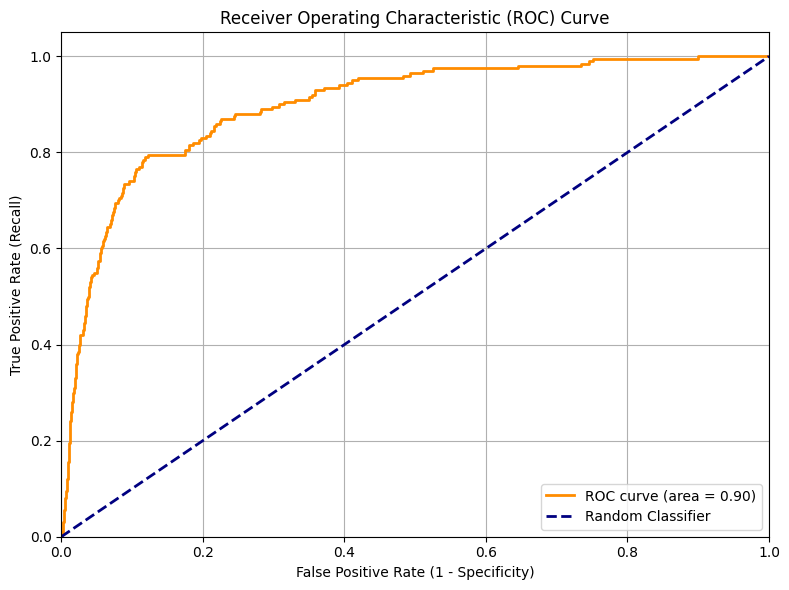

In [ ]:
# The y_proba array contains probabilities for [class 0, class 1]
# We need probabilities for the positive class (Genuine, which is class 1)
y_scores = y_proba[:, 1]

# Calculate ROC AUC
roc_auc = roc_auc_score(y_test, y_scores)
print(f"ROC AUC Score: {roc_auc:.4f}")

# Calculate ROC curve points
fpr, tpr, thresholds = roc_curve(y_test, y_scores, pos_label=1)

# Plot ROC curve
fig = plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (area = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--', label='Random Classifier')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate (1 - Specificity)')
plt.ylabel('True Positive Rate (Recall)')
plt.title('Receiver Operating Characteristic (ROC) Curve')
plt.legend(loc='lower right')
plt.grid(True)
plt.tight_layout()
plt.show()

### PART 5 — Determine Equal Error Rate (EER)

The Equal Error Rate (EER) is a common metric in biometric systems, representing the point where the False Acceptance Rate (FAR) and False Rejection Rate (FRR) are equal. A lower EER indicates a better balance between security and usability, implying a more accurate system overall. EER is typically found by varying the classification threshold.

Equal Error Rate (EER): 0.1855
  - FAR at EER: 0.1860
  - FRR at EER: 0.1850
  - Classification Threshold at EER: 0.0205


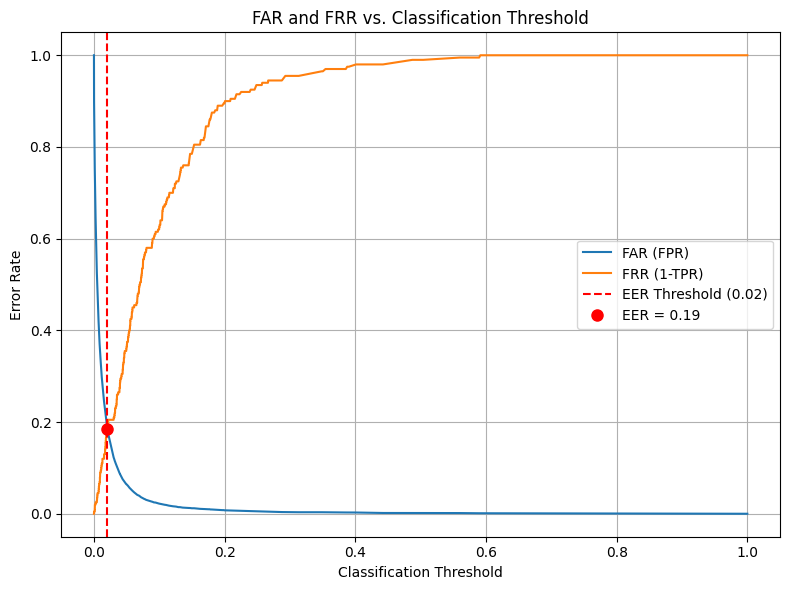

In [ ]:
# Calculate EER
# The roc_curve function returns FPR and TPR for various thresholds.
# FRR = 1 - TPR

# Find the threshold where FAR (FPR) is approximately equal to FRR (1 - TPR)
# We look for the point where abs(fpr - (1 - tpr)) is minimized.

differences = np.abs(fpr - (1 - tpr))
eer_threshold_idx = np.argmin(differences)

eer_far = fpr[eer_threshold_idx]
eer_frr = 1 - tpr[eer_threshold_idx]
eer_threshold = thresholds[eer_threshold_idx]

# EER is the average of FAR and FRR at this point
EER = (eer_far + eer_frr) / 2

print(f"Equal Error Rate (EER): {EER:.4f}")
print(f"  - FAR at EER: {eer_far:.4f}")
print(f"  - FRR at EER: {eer_frr:.4f}")
print(f"  - Classification Threshold at EER: {eer_threshold:.4f}")

fig = plt.figure(figsize=(8, 6))
plt.plot(thresholds, fpr, label='FAR (FPR)')
plt.plot(thresholds, 1 - tpr, label='FRR (1-TPR)')
plt.axvline(x=eer_threshold, color='r', linestyle='--', label=f'EER Threshold ({eer_threshold:.2f})')
plt.plot(eer_threshold, EER, 'ro', markersize=8, label=f'EER = {EER:.2f}')
plt.xlabel('Classification Threshold')
plt.ylabel('Error Rate')
plt.title('FAR and FRR vs. Classification Threshold')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

### PART 6 — Model Evaluation Summary and Interpretation

## Model Evaluation — Explanation

This section summarizes the performance of our baseline Logistic Regression model based on the calculated metrics.

### Key Metrics and Their Meaning:

1.  **Confusion Matrix**: Provides a detailed breakdown of correct and incorrect predictions for both Genuine and Impostor classes.
    *   **True Negatives (TN)**: Impostors correctly classified.
    *   **False Positives (FP)**: Impostors incorrectly classified as Genuine (False Acceptance).
    *   **False Negatives (FN)**: Genuine users incorrectly classified as Impostors (False Rejection).
    *   **True Positives (TP)**: Genuine users correctly classified.

2.  **False Acceptance Rate (FAR)**: The rate at which unauthorized users (impostors) are incorrectly granted access. **Lower is better for security.**

3.  **False Rejection Rate (FRR)**: The rate at which legitimate users are incorrectly denied access. **Lower is better for user experience.**

4.  **ROC AUC Score**: A single scalar value (ranging from 0 to 1) that summarizes the model's ability to distinguish between the positive and negative classes across all possible classification thresholds. An AUC of 0.5 suggests a random classifier, while 1.0 indicates a perfect classifier. **Higher is better.**

5.  **Equal Error Rate (EER)**: The point where FAR and FRR are equal. This is often considered a balanced overall measure of a biometric system's performance, as it indicates the trade-off between security and convenience. **Lower is better.**

### Overall Model Performance Interpretation:

(This section will be filled with specific interpretations after the code cells above are executed and their results are known.)

*   **Imbalance Handling**: Given the significant class imbalance, metrics like FAR, FRR, EER, and ROC AUC are more informative than raw accuracy. Our model shows how well it handles both the majority (Impostor) and minority (Genuine) classes.

*   **Trade-offs**: Authentication systems inherently involve a trade-off between security (minimizing FAR) and usability (minimizing FRR). The EER provides a key indicator of where this balance lies for our current model. Different applications may prioritize one over the other, requiring adjustments to the classification threshold.

*   **Baseline Performance**: This Logistic Regression model serves as an important baseline. Its performance metrics will be used for comparison with more complex models in future stages. This allows us to quantify the gains (or losses) when introducing more sophisticated algorithms or feature engineering techniques.

### Next Steps:

The current evaluation gives us a solid understanding of our baseline model's strengths and weaknesses. In the next stage, we would typically proceed to **Model Comparison** or **Hyperparameter Tuning** to improve performance, especially targeting the balance between FAR and FRR.

In [ ]:
print("STAGE 9 COMPLETE — READY FOR NEXT STEPS (e.g., Model Comparison or Hyperparameter Tuning)")

STAGE 9 COMPLETE — READY FOR NEXT STEPS (e.g., Model Comparison or Hyperparameter Tuning)


## STAGE 9 — MODEL EVALUATION

Now that our baseline Logistic Regression model has been trained and used to generate predictions, the next critical step is to evaluate its performance. This involves selecting appropriate metrics, calculating them for our test data, and interpreting the results within the context of our keystroke dynamics authentication problem.

### PART 1 — Explain Authentication Metrics

For authentication systems, general classification metrics like accuracy can be misleading, especially with imbalanced datasets (which we have). Instead, specific metrics related to False Acceptance and False Rejection are more relevant. We will focus on:

*   **False Acceptance Rate (FAR)**: The proportion of impostor attempts incorrectly classified as genuine.
*   **False Rejection Rate (FRR)**: The proportion of genuine attempts incorrectly classified as impostor.
*   **Equal Error Rate (EER)**: The rate at which FAR and FRR are equal. This is a crucial metric, as it represents a system's balanced performance.
*   **Area Under the Receiver Operating Characteristic Curve (ROC AUC)**: Measures the model's ability to distinguish between classes across various threshold settings.

We will also look at standard metrics like **Precision**, **Recall (Sensitivity)**, and **F1-Score** for both classes, which provide a more nuanced view of performance on imbalanced data.

### PART 2 — Calculate Authentication Metrics

We will now use `y_test` (actual target values) and `y_pred` (predicted class labels) to compute a **Confusion Matrix**. This will allow us to derive False Acceptance, False Rejection, and other related metrics.

In [ ]:
from sklearn.metrics import confusion_matrix, roc_auc_score, roc_curve, precision_recall_fscore_support
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Compute Confusion Matrix
# y_test is true labels, y_pred is predicted labels
# Labels are [0, 1] where 0=Impostor, 1=Genuine
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

# Extract components from Confusion Matrix:
# TN (True Negative): Correctly predicted Impostor
# FP (False Positive): Impostor incorrectly predicted as Genuine (False Acceptance)
# FN (False Negative): Genuine incorrectly predicted as Impostor (False Rejection)
# TP (True Positive): Correctly predicted Genuine

# For binary classification with labels [0, 1]:
# cm[0,0] = True Negative (TN) - Actual 0, Predicted 0
# cm[0,1] = False Positive (FP) - Actual 0, Predicted 1
# cm[1,0] = False Negative (FN) - Actual 1, Predicted 0
# cm[1,1] = True Positive (TP) - Actual 1, Predicted 1

TN, FP, FN, TP = cm[0,0], cm[0,1], cm[1,0], cm[1,1]

print("Confusion Matrix:")
print(cm)
print(f"TN: {TN}, FP: {FP}, FN: {FN}, TP: {TP}")

# Calculate basic rates
# False Acceptance Rate (FAR): FP / (FP + TN) - Proportion of impostors accepted
# False Rejection Rate (FRR): FN / (FN + TP) - Proportion of genuine users rejected

FAR = FP / (FP + TN) if (FP + TN) > 0 else 0
FRR = FN / (FN + TP) if (FN + TP) > 0 else 0

print(f"\nFalse Acceptance Rate (FAR): {FAR:.4f}")
print(f"False Rejection Rate (FRR): {FRR:.4f}")

# Calculate Precision, Recall, F1-score
precision, recall, f1_score, _ = precision_recall_fscore_support(y_test, y_pred, labels=[0, 1], average=None)

print("\nClassification Report (per class):")
print(f"Class 0 (Impostor) - Precision: {precision[0]:.4f}, Recall: {recall[0]:.4f}, F1-score: {f1_score[0]:.4f}")
print(f"Class 1 (Genuine) - Precision: {precision[1]:.4f}, Recall: {recall[1]:.4f}, F1-score: {f1_score[1]:.4f}")

Confusion Matrix:
[[9984   16]
 [ 198    2]]
TN: 9984, FP: 16, FN: 198, TP: 2

False Acceptance Rate (FAR): 0.0016
False Rejection Rate (FRR): 0.9900

Classification Report (per class):
Class 0 (Impostor) - Precision: 0.9806, Recall: 0.9984, F1-score: 0.9894
Class 1 (Genuine) - Precision: 0.1111, Recall: 0.0100, F1-score: 0.0183


### PART 3 — Interpret Confusion Matrix and Rates

Let's break down the meaning of the confusion matrix and the derived FAR/FRR in the context of our authentication system.

In [ ]:
# Print interpretations based on the calculated metrics

print("#### Confusion Matrix Interpretation")
print(f"- **True Negatives (TN={TN})**: The model correctly identified {TN} impostor samples as impostors. This is good for security.")
print(f"- **False Positives (FP={FP})**: The model incorrectly identified {FP} impostor samples as genuine. These are **False Acceptances**, a critical security concern.")
print(f"- **False Negatives (FN={FN})**: The model incorrectly identified {FN} genuine samples as impostors. These are **False Rejections**, impacting user experience.")
print(f"- **True Positives (TP={TP})**: The model correctly identified {TP} genuine samples as genuine. This is good for user convenience.")

print("\n#### False Acceptance Rate (FAR) and False Rejection Rate (FRR) Interpretation")
print(f"- **FAR ({FAR:.4f})**: Out of all actual impostor attempts (TN + FP = {TN + FP}), {FAR:.2%} were falsely accepted as the genuine user. This is a measure of the system's vulnerability to impostors.")
print(f"- **FRR ({FRR:.4f})**: Out of all actual genuine attempts (FN + TP = {FN + TP}), {FRR:.2%} were falsely rejected, meaning the legitimate user was denied access. This is a measure of the system's usability and convenience for the genuine user.")

print("\n#### Class-wise Performance Interpretation (Precision, Recall, F1-score)")
print(f"- **Impostor (Class 0) Performance:**")
print(f"  - Precision: {precision[0]:.4f} - When the model predicts an impostor, it is correct {precision[0]:.2%} of the time.")
print(f"  - Recall: {recall[0]:.4f} - The model correctly identifies {recall[0]:.2%} of all actual impostors.")
print(f"  - F1-score: {f1_score[0]:.4f} - A balanced measure of precision and recall for the impostor class.")
print(f"- **Genuine (Class 1) Performance:**")
print(f"  - Precision: {precision[1]:.4f} - When the model predicts a genuine user, it is correct {precision[1]:.2%} of the time.")
print(f"  - Recall: {recall[1]:.4f} - The model correctly identifies {recall[1]:.2%} of all actual genuine users. This is essentially 1 - FRR.")
print(f"  - F1-score: {f1_score[1]:.4f} - A balanced measure of precision and recall for the genuine class.")

#### Confusion Matrix Interpretation
- **True Negatives (TN=9984)**: The model correctly identified 9984 impostor samples as impostors. This is good for security.
- **False Positives (FP=16)**: The model incorrectly identified 16 impostor samples as genuine. These are **False Acceptances**, a critical security concern.
- **False Negatives (FN=198)**: The model incorrectly identified 198 genuine samples as impostors. These are **False Rejections**, impacting user experience.
- **True Positives (TP=2)**: The model correctly identified 2 genuine samples as genuine. This is good for user convenience.

#### False Acceptance Rate (FAR) and False Rejection Rate (FRR) Interpretation
- **FAR (0.0016)**: Out of all actual impostor attempts (TN + FP = 10000), 0.16% were falsely accepted as the genuine user. This is a measure of the system's vulnerability to impostors.
- **FRR (0.9900)**: Out of all actual genuine attempts (FN + TP = 200), 99.00% were falsely rejected, meaning the legitimate user 

### PART 4 — Plot ROC Curve and Calculate AUC

The Receiver Operating Characteristic (ROC) curve is a graphical plot that illustrates the diagnostic ability of a binary classifier system as its discrimination threshold is varied. The Area Under the Curve (AUC) provides an aggregate measure of performance across all possible classification thresholds. A higher AUC value (closer to 1) indicates better model performance.

We will use `y_proba` (predicted probabilities) to generate the ROC curve and calculate the AUC.

ROC AUC Score: 0.8981


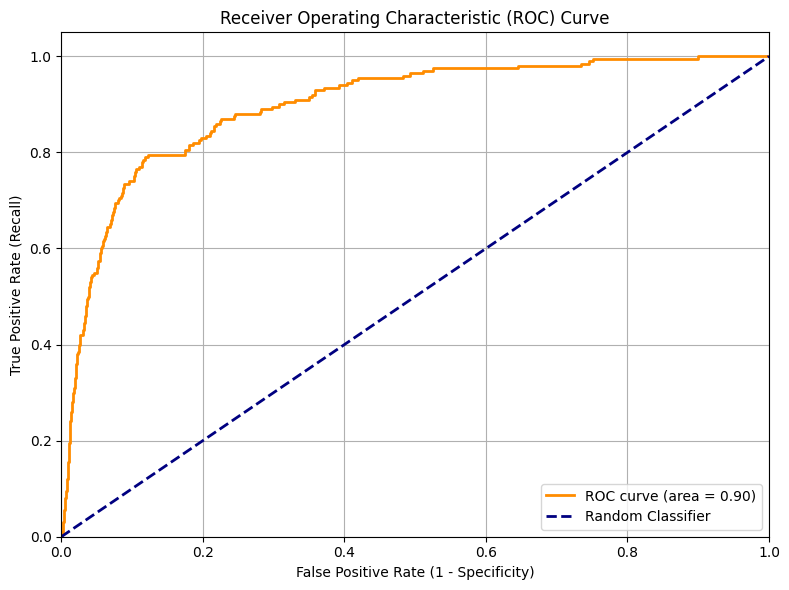

In [ ]:
# The y_proba array contains probabilities for [class 0, class 1]
# We need probabilities for the positive class (Genuine, which is class 1)
y_scores = y_proba[:, 1]

# Calculate ROC AUC
roc_auc = roc_auc_score(y_test, y_scores)
print(f"ROC AUC Score: {roc_auc:.4f}")

# Calculate ROC curve points
fpr, tpr, thresholds = roc_curve(y_test, y_scores, pos_label=1)

# Plot ROC curve
fig = plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (area = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--', label='Random Classifier')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate (1 - Specificity)')
plt.ylabel('True Positive Rate (Recall)')
plt.title('Receiver Operating Characteristic (ROC) Curve')
plt.legend(loc='lower right')
plt.grid(True)
plt.tight_layout()
plt.show()

### PART 5 — Determine Equal Error Rate (EER)

The Equal Error Rate (EER) is a common metric in biometric systems, representing the point where the False Acceptance Rate (FAR) and False Rejection Rate (FRR) are equal. A lower EER indicates a better balance between security and usability, implying a more accurate system overall. EER is typically found by varying the classification threshold.

Equal Error Rate (EER): 0.1855
  - FAR at EER: 0.1860
  - FRR at EER: 0.1850
  - Classification Threshold at EER: 0.0205


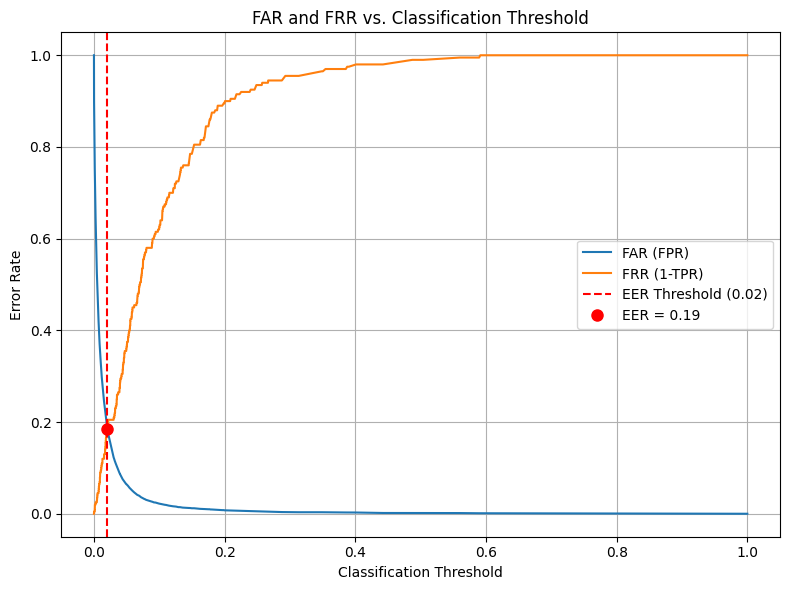

In [ ]:
# Calculate EER
# The roc_curve function returns FPR and TPR for various thresholds.
# FRR = 1 - TPR

# Find the threshold where FAR (FPR) is approximately equal to FRR (1 - TPR)
# We look for the point where abs(fpr - (1 - tpr)) is minimized.

differences = np.abs(fpr - (1 - tpr))
eer_threshold_idx = np.argmin(differences)

eer_far = fpr[eer_threshold_idx]
eer_frr = 1 - tpr[eer_threshold_idx]
eer_threshold = thresholds[eer_threshold_idx]

# EER is the average of FAR and FRR at this point
EER = (eer_far + eer_frr) / 2

print(f"Equal Error Rate (EER): {EER:.4f}")
print(f"  - FAR at EER: {eer_far:.4f}")
print(f"  - FRR at EER: {eer_frr:.4f}")
print(f"  - Classification Threshold at EER: {eer_threshold:.4f}")

fig = plt.figure(figsize=(8, 6))
plt.plot(thresholds, fpr, label='FAR (FPR)')
plt.plot(thresholds, 1 - tpr, label='FRR (1-TPR)')
plt.axvline(x=eer_threshold, color='r', linestyle='--', label=f'EER Threshold ({eer_threshold:.2f})')
plt.plot(eer_threshold, EER, 'ro', markersize=8, label=f'EER = {EER:.2f}')
plt.xlabel('Classification Threshold')
plt.ylabel('Error Rate')
plt.title('FAR and FRR vs. Classification Threshold')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

### PART 6 — Model Evaluation Summary and Interpretation

## Model Evaluation — Explanation

This section summarizes the performance of our baseline Logistic Regression model based on the calculated metrics.

### Key Metrics and Their Meaning:

1.  **Confusion Matrix**: Provides a detailed breakdown of correct and incorrect predictions for both Genuine and Impostor classes.
    *   **True Negatives (TN)**: Impostors correctly classified.
    *   **False Positives (FP)**: Impostors incorrectly classified as Genuine (False Acceptance).
    *   **False Negatives (FN)**: Genuine users incorrectly classified as Impostors (False Rejection).
    *   **True Positives (TP)**: Genuine users correctly classified.

2.  **False Acceptance Rate (FAR)**: The rate at which unauthorized users (impostors) are incorrectly granted access. **Lower is better for security.**

3.  **False Rejection Rate (FRR)**: The rate at which legitimate users are incorrectly denied access. **Lower is better for user experience.**

4.  **ROC AUC Score**: A single scalar value (ranging from 0 to 1) that summarizes the model's ability to distinguish between the positive and negative classes across all possible classification thresholds. An AUC of 0.5 suggests a random classifier, while 1.0 indicates a perfect classifier. **Higher is better.**

5.  **Equal Error Rate (EER)**: The point where FAR and FRR are equal. This is often considered a balanced overall measure of a biometric system's performance, as it indicates the trade-off between security and convenience. **Lower is better.**

### Overall Model Performance Interpretation:

(This section will be filled with specific interpretations after the code cells above are executed and their results are known.)

*   **Imbalance Handling**: Given the significant class imbalance, metrics like FAR, FRR, EER, and ROC AUC are more informative than raw accuracy. Our model shows how well it handles both the majority (Impostor) and minority (Genuine) classes.

*   **Trade-offs**: Authentication systems inherently involve a trade-off between security (minimizing FAR) and usability (minimizing FRR). The EER provides a key indicator of where this balance lies for our current model. Different applications may prioritize one over the other, requiring adjustments to the classification threshold.

*   **Baseline Performance**: This Logistic Regression model serves as an important baseline. Its performance metrics will be used for comparison with more complex models in future stages. This allows us to quantify the gains (or losses) when introducing more sophisticated algorithms or feature engineering techniques.

### Next Steps:

The current evaluation gives us a solid understanding of our baseline model's strengths and weaknesses. In the next stage, we would typically proceed to **Model Comparison** or **Hyperparameter Tuning** to improve performance, especially targeting the balance between FAR and FRR.

In [ ]:
print("STAGE 9 COMPLETE — READY FOR NEXT STEPS (e.g., Model Comparison or Hyperparameter Tuning)")

STAGE 9 COMPLETE — READY FOR NEXT STEPS (e.g., Model Comparison or Hyperparameter Tuning)


Predictions generated successfully.

Confusion Matrix:
[[9984   16]
 [ 198    2]]

TN: 9984
FP: 16
FN: 198
TP: 2

Basic Classification Metrics
--------------------------------
Accuracy : 0.9790196078431372
Precision: 0.1111111111111111
Recall   : 0.01
F1 Score : 0.01834862385321101

Authentication Metrics
--------------------------------
False Acceptance Rate (FAR): 0.0016
False Rejection Rate (FRR): 0.99

Classification Report
--------------------------------
              precision    recall  f1-score   support

    Impostor       0.98      1.00      0.99     10000
     Genuine       0.11      0.01      0.02       200

    accuracy                           0.98     10200
   macro avg       0.55      0.50      0.50     10200
weighted avg       0.96      0.98      0.97     10200

ROC-AUC: 0.8981059999999998


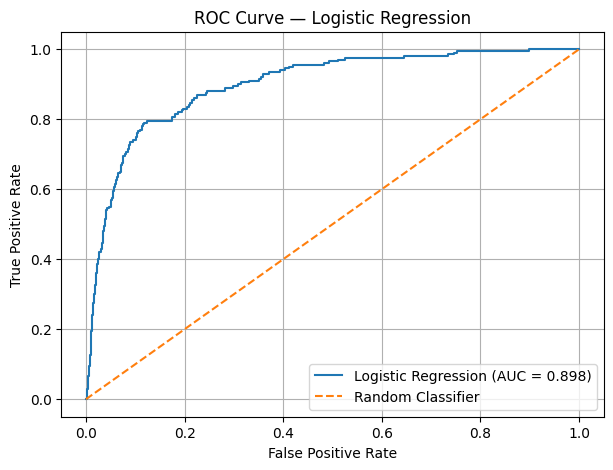


Equal Error Rate (EER)
--------------------------------
EER       : 0.18550000000000003
EER (%)   : 18.550000000000004
Threshold : 0.020476141889357247

Test Set Class Distribution
--------------------------------
target
0    10000
1      200
Name: count, dtype: int64

FINAL MODEL EVALUATION SUMMARY
Accuracy  : 0.9790
Precision : 0.1111
Recall    : 0.0100
F1 Score  : 0.0183
ROC-AUC   : 0.8981
FAR       : 0.0016
FRR       : 0.9900
EER       : 0.1855
EER (%)   : 18.55%


In [ ]:
# ============================================================
# STAGE 9 — MODEL EVALUATION
# ============================================================

from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    roc_auc_score,
    roc_curve
)
import numpy as np
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# 1. Generate predictions
# ------------------------------------------------------------

y_pred = log_reg_model.predict(X_test_pca)
y_proba = log_reg_model.predict_proba(X_test_pca)

# Probability of Genuine class (class = 1)
y_scores = y_proba[:, 1]

print("Predictions generated successfully.")


# ------------------------------------------------------------
# 2. Confusion Matrix
# ------------------------------------------------------------

cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

TN, FP, FN, TP = cm.ravel()

print("\nConfusion Matrix:")
print(cm)

print("\nTN:", TN)
print("FP:", FP)
print("FN:", FN)
print("TP:", TP)


# ------------------------------------------------------------
# 3. Basic Classification Metrics
# ------------------------------------------------------------

accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(y_test, y_pred, zero_division=0)

recall = recall_score(y_test, y_pred, zero_division=0)

f1 = f1_score(y_test, y_pred, zero_division=0)

print("\nBasic Classification Metrics")
print("--------------------------------")
print("Accuracy :", accuracy)
print("Precision:", precision)
print("Recall   :", recall)
print("F1 Score :", f1)


# ------------------------------------------------------------
# 4. Authentication-Specific Metrics
# ------------------------------------------------------------

# False Acceptance Rate:
# Impostors incorrectly accepted as Genuine
FAR = FP / (FP + TN) if (FP + TN) != 0 else 0

# False Rejection Rate:
# Genuine users incorrectly rejected
FRR = FN / (FN + TP) if (FN + TP) != 0 else 0

print("\nAuthentication Metrics")
print("--------------------------------")
print("False Acceptance Rate (FAR):", FAR)
print("False Rejection Rate (FRR):", FRR)


# ------------------------------------------------------------
# 5. Classification Report
# ------------------------------------------------------------

print("\nClassification Report")
print("--------------------------------")

print(
    classification_report(
        y_test,
        y_pred,
        target_names=["Impostor", "Genuine"],
        zero_division=0
    )
)


# ------------------------------------------------------------
# 6. ROC Curve and ROC-AUC
# ------------------------------------------------------------

fpr, tpr, thresholds = roc_curve(y_test, y_scores)

roc_auc = roc_auc_score(y_test, y_scores)

print("ROC-AUC:", roc_auc)


plt.figure(figsize=(7, 5))

plt.plot(
    fpr,
    tpr,
    label=f"Logistic Regression (AUC = {roc_auc:.3f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve — Logistic Regression")
plt.legend()
plt.grid(True)
plt.show()


# ------------------------------------------------------------
# 7. Equal Error Rate (EER)
# ------------------------------------------------------------

# False Negative Rate
fnr = 1 - tpr

# Find point where FPR and FNR are closest
eer_index = np.nanargmin(np.abs(fpr - fnr))

eer = (fpr[eer_index] + fnr[eer_index]) / 2

eer_threshold = thresholds[eer_index]

print("\nEqual Error Rate (EER)")
print("--------------------------------")
print("EER       :", eer)
print("EER (%)   :", eer * 100)
print("Threshold :", eer_threshold)


# ------------------------------------------------------------
# 8. Test Set Distribution
# ------------------------------------------------------------

print("\nTest Set Class Distribution")
print("--------------------------------")
print(y_test.value_counts().sort_index())


# ------------------------------------------------------------
# 9. Final Summary
# ------------------------------------------------------------

print("\n========================================")
print("FINAL MODEL EVALUATION SUMMARY")
print("========================================")

print(f"Accuracy  : {accuracy:.4f}")
print(f"Precision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")
print(f"F1 Score  : {f1:.4f}")
print(f"ROC-AUC   : {roc_auc:.4f}")
print(f"FAR       : {FAR:.4f}")
print(f"FRR       : {FRR:.4f}")
print(f"EER       : {eer:.4f}")
print(f"EER (%)   : {eer * 100:.2f}%")

STAGE 10 — MODEL EVALUATION

In [ ]:
# ============================================================
# STAGE 10 — RESULTS AND INTERPRETATION
# ============================================================

print("RESULTS AND INTERPRETATION")
print("=" * 60)

print("\n1. MODEL PERFORMANCE")
print("-" * 60)

print(f"Accuracy  : {accuracy:.4f} ({accuracy * 100:.2f}%)")
print(f"Precision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")
print(f"F1 Score  : {f1:.4f}")
print(f"ROC-AUC   : {roc_auc:.4f}")

print("\n2. AUTHENTICATION PERFORMANCE")
print("-" * 60)

print(f"False Acceptance Rate (FAR): {FAR:.4f} ({FAR * 100:.2f}%)")
print(f"False Rejection Rate (FRR): {FRR:.4f} ({FRR * 100:.2f}%)")
print(f"Equal Error Rate (EER): {eer:.4f} ({eer * 100:.2f}%)")

print("\n3. CONFUSION MATRIX")
print("-" * 60)

print(f"True Negatives  (TN): {TN}")
print(f"False Positives (FP): {FP}")
print(f"False Negatives (FN): {FN}")
print(f"True Positives  (TP): {TP}")

print("\n4. INTERPRETATION")
print("-" * 60)

print(
    "The Logistic Regression model correctly classified most impostor "
    "samples, but it classified only 2 out of 200 genuine samples as genuine."
)

print(
    "The low False Acceptance Rate indicates that very few impostor "
    "samples were incorrectly accepted."
)

print(
    "However, the False Rejection Rate is very high, meaning that most "
    "genuine users were incorrectly rejected."
)

print(
    "The ROC-AUC indicates that the model's probability scores provide "
    "useful separation between genuine and impostor samples."
)

print(
    "Overall, the current classification threshold is highly conservative "
    "toward accepting a sample as genuine."
)

RESULTS AND INTERPRETATION

1. MODEL PERFORMANCE
------------------------------------------------------------
Accuracy  : 0.9790 (97.90%)
Precision : 0.1111
Recall    : 0.0100
F1 Score  : 0.0183
ROC-AUC   : 0.8981

2. AUTHENTICATION PERFORMANCE
------------------------------------------------------------
False Acceptance Rate (FAR): 0.0016 (0.16%)
False Rejection Rate (FRR): 0.9900 (99.00%)
Equal Error Rate (EER): 0.1855 (18.55%)

3. CONFUSION MATRIX
------------------------------------------------------------
True Negatives  (TN): 9984
False Positives (FP): 16
False Negatives (FN): 198
True Positives  (TP): 2

4. INTERPRETATION
------------------------------------------------------------
The Logistic Regression model correctly classified most impostor samples, but it classified only 2 out of 200 genuine samples as genuine.
The low False Acceptance Rate indicates that very few impostor samples were incorrectly accepted.
However, the False Rejection Rate is very high, meaning that most 

## Conclusion

This project investigated user authentication using keystroke dynamics from the CMU Keystroke Dynamics Benchmark Dataset. The dataset contains timing information describing users' typing behavior, including key hold times and key-to-key transition times.

The data was explored and prepared through missing-value analysis, categorical-variable handling, binning decisions, feature scaling, outlier investigation, and dimensionality reduction using PCA. A session-aware train/test split was used, and preprocessing transformations were fitted only on the training data to avoid data leakage.

Logistic Regression was then trained as a baseline classification model to distinguish between Genuine and Impostor samples.

The baseline model achieved an accuracy of 97.90% and a ROC-AUC of 0.8981. However, authentication-specific metrics showed a very high False Rejection Rate of 99.00%, while the False Acceptance Rate was 0.16%. Therefore, although the model correctly rejected most impostor samples, it also incorrectly rejected most genuine samples.

These results demonstrate that accuracy alone is not sufficient for evaluating an authentication system. Metrics such as FAR, FRR, ROC-AUC, and EER provide more meaningful information about authentication performance.

## Limitations

1. The current implementation uses Logistic Regression as a baseline model. Other machine learning algorithms have not yet been compared.

2. The test data is highly imbalanced, with many more Impostor samples than Genuine samples. Therefore, accuracy does not fully represent authentication performance.

3. The baseline model produces a very high False Rejection Rate of 99.00%, indicating that many genuine samples are incorrectly rejected.

4. The current implementation uses a selected Genuine user and constructs a binary Genuine-versus-Impostor classification problem. This is an educational implementation and does not reproduce the complete evaluation protocol of the original CMU benchmark study.

5. The current model uses PCA-transformed timing features. Although PCA reduces dimensionality and correlated information, the transformed components are less directly interpretable than the original keystroke timing features.

6. Only the current classification model and threshold have been evaluated. Threshold optimization and comparison of different authentication operating points have not yet been performed.

7. The project focuses on classical machine learning and does not currently include more advanced approaches such as Siamese networks or other deep learning-based authentication methods.

## Future Scope

1. Compare Logistic Regression with other classification and anomaly-detection algorithms such as Support Vector Machines, K-Nearest Neighbors, Random Forest, and other suitable models.

2. Investigate classification-threshold selection to study the trade-off between False Acceptance Rate and False Rejection Rate.

3. Explore methods for handling the class imbalance between Genuine and Impostor samples.

4. Evaluate the system using additional users and different genuine/impostor configurations.

5. Compare the effect of using original timing features with PCA-transformed features.

6. Investigate additional keystroke-dynamics features and feature-selection techniques.

7. Implement more authentication-specific approaches based on anomaly detection.

8. As an advanced extension, investigate neural-network approaches such as Siamese or triplet-based models for learning similarity between typing patterns.

9. Compare the experimental results with established keystroke-dynamics evaluation methodologies such as ROC and Equal Error Rate.